# ASAP: local-HPO + persistent-checkpoint + paper-core HOLMS edition

This version keeps the LSScore formulation unchanged, adds the same second-stage VALIDATION-only local refinement procedure across datasets, persists expensive stages to Google Drive, and keeps HOLMS faithful to the published core method. HOLMS speed improvements use compiled Euclidean-distance computation and resumable pair processing only; they do not change 4-grams, USE embeddings, greedy one-to-one matching, AUC semantic scoring, ROUGE-1 recall, or the Gaussian combination.


In [ ]:
# Colab setup
!nvidia-smi
%pip install -q sacrebleu rouge-score bert-score sentence-transformers numpy pandas scipy tqdm scikit-learn matplotlib


Wed Sep 30 06:34:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   33C    P0             62W /  400W |    4578MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
import re
import json
import warnings
import numpy as np
import pandas as pd
from itertools import product as iterproduct
from tqdm.auto import tqdm

from scipy.stats import pearsonr, spearmanr, kendalltau
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

from sacrebleu import sentence_bleu
from rouge_score import rouge_scorer
from bert_score import score as bert_score
from sentence_transformers import SentenceTransformer

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
)

# ============================================================
# Reproducibility
# ============================================================

SEED = 42

SEARCH_STABILITY_SEEDS = [
    2026,
    42,
    1234,
]

SEARCH_SAMPLE_SIZE_PER_SEED = 800


# ============================================================
# LSScore configuration
# ============================================================

N_LIST = [
    1,
    2,
    3,
]

EMBEDDING_MODEL = "all-mpnet-base-v2"


# ============================================================
# Baseline configuration
# ============================================================

BLEU_SMOOTH_METHOD = "exp"

BERTSCORE_MODEL = "roberta-large"

BERTSCORE_BATCH_SIZE = 32

BERTSCORE_RESCALE_WITH_BASELINE = True


# ============================================================
# ORIGINAL LSScore HYPERPARAMETER SEARCH SPACE
# ============================================================
#
# This is the thesis/original search space:
#
# tau:
#   8 values
#
# delta:
#   7 values
#
# alpha:
#   8 fixed n-gram weight combinations
#
# beta:
#   4 values
#
# BP:
#   True / False
#
# Total:
#   8 × 7 × 8 × 4 × 2
#   = 3,584 configurations
#
# ============================================================


# ------------------------------------------------------------
# Semantic similarity threshold tau
# ------------------------------------------------------------

TAU_VALUES = [
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
]


# ------------------------------------------------------------
# Semantic discount delta
# ------------------------------------------------------------

DELTA_VALUES = [
    0.60,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90,
    0.95,
]


# ------------------------------------------------------------
# N-gram aggregation weights alpha
#
# alpha_1 = unigram
# alpha_2 = bigram
# alpha_3 = trigram
# ------------------------------------------------------------

ALPHA_VALUES = [
    (0.50, 0.35, 0.15),
    (0.45, 0.40, 0.15),
    (0.40, 0.40, 0.20),
    (0.35, 0.45, 0.20),
    (0.30, 0.50, 0.20),
    (0.25, 0.55, 0.20),
    (0.20, 0.60, 0.20),
    (0.20, 0.55, 0.25),
]


# ------------------------------------------------------------
# F-beta values
# ------------------------------------------------------------

BETA_VALUES = [
    0.50,
    0.75,
    1.00,
    2.00,
]


# ------------------------------------------------------------
# Brevity penalty
# ------------------------------------------------------------

USE_BP_VALUES = [
    True,
    False,
]


# ============================================================
# Full HPO search universe
# ============================================================

FULL_SEARCH_SPACE = list(
    iterproduct(
        TAU_VALUES,
        DELTA_VALUES,
        ALPHA_VALUES,
        BETA_VALUES,
        USE_BP_VALUES,
    )
)


# ============================================================
# Sanity checks
# ============================================================

EXPECTED_SEARCH_SIZE = (
    len(TAU_VALUES)
    * len(DELTA_VALUES)
    * len(ALPHA_VALUES)
    * len(BETA_VALUES)
    * len(USE_BP_VALUES)
)

assert (
    len(FULL_SEARCH_SPACE)
    == EXPECTED_SEARCH_SIZE
)

assert (
    len(FULL_SEARCH_SPACE)
    == 3584
)


print(
    "Tau values:",
    len(TAU_VALUES),
)

print(
    "Delta values:",
    len(DELTA_VALUES),
)

print(
    "Alpha configurations:",
    len(ALPHA_VALUES),
)

print(
    "Beta values:",
    len(BETA_VALUES),
)

print(
    "BP configurations:",
    len(USE_BP_VALUES),
)

print(
    "\nFull LSScore search space:",
    f"{len(FULL_SEARCH_SPACE):,}",
    "configurations",
)

print(
    "Random-search stability seeds:",
    SEARCH_STABILITY_SEEDS,
)

print(
    "Configurations sampled per seed:",
    SEARCH_SAMPLE_SIZE_PER_SEED,
)


# ============================================================
# Validation pairwise settings
# ============================================================
#
# HPO uses a deterministic sample of within-prompt pairs.
# Final TEST pairwise accuracy remains exact.
# ============================================================

VAL_PAIRWISE_SAMPLE = 20_000

Tau values: 8
Delta values: 7
Alpha configurations: 8
Beta values: 4
BP configurations: 2

Full LSScore search space: 3,584 configurations
Random-search stability seeds: [2026, 42, 1234]
Configurations sampled per seed: 800


## 1. Load dataset

In [ ]:
DATASET_NAME = "ASAP"

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

DATA_CANDIDATES = [
    "/content/drive/MyDrive/Colab Notebooks/Optimized Code /dataset/ASAP.csv",
    "/mnt/data/ASAP.csv",
    "ASAP.csv",
]

def first_existing(paths):
    for path in paths:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        "None of these paths exists:\n" + "\n".join(paths)
    )

DATA_PATH = first_existing(DATA_CANDIDATES)
raw_df = pd.read_csv(DATA_PATH)

required = ["id", "text", "prompt", "score", "min_score", "max_score"]
missing = [c for c in required if c not in raw_df.columns]
if missing:
    raise KeyError(f"ASAP file is missing columns: {missing}")

df = raw_df[required].copy()
df.columns = [
    "item_id", "text", "prompt_id", "human_score",
    "score_min", "score_max"
]

df["item_id"] = df["item_id"].astype(str)
for col in ["human_score", "score_min", "score_max"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=[
        "item_id", "text", "prompt_id", "human_score",
        "score_min", "score_max"
    ]
).copy()

df["prompt_title"] = df["prompt_id"].astype(str)

print(
    f"ASAP loaded: {len(df):,} essays | "
    f"{df['prompt_id'].nunique()} prompts"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ASAP loaded: 12,976 essays | 8 prompts


In [ ]:
# ============================================================
# Persistent checkpoint system (Google Drive)
# ============================================================
# Saves completed expensive stages so a Colab/kernel restart does not force
# the whole pipeline to be recomputed. Checkpoints are dataset-specific.

import os as _ckpt_os
import pickle as _ckpt_pickle
from datetime import datetime as _ckpt_datetime

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/Optimized Code/"
    "checkpoints/asap"
)
_ckpt_os.makedirs(CHECKPOINT_DIR, exist_ok=True)


def checkpoint_path(name):
    return _ckpt_os.path.join(CHECKPOINT_DIR, f"{name}.pkl")


def save_checkpoint(name, variable_names):
    """Atomically persist selected global variables to Google Drive."""
    payload = {
        "checkpoint": name,
        "dataset": "ASAP",
        "saved_at": _ckpt_datetime.now().isoformat(timespec="seconds"),
        "variables": {},
    }
    missing = []
    for var_name in variable_names:
        if var_name in globals():
            payload["variables"][var_name] = globals()[var_name]
        else:
            missing.append(var_name)

    path = checkpoint_path(name)
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        _ckpt_pickle.dump(payload, f, protocol=_ckpt_pickle.HIGHEST_PROTOCOL)
    _ckpt_os.replace(tmp, path)

    print(
        f"✓ Checkpoint saved: {name} | "
        f"{len(payload['variables'])} variables | {path}"
    )
    if missing:
        print("  Not yet defined (skipped):", ", ".join(missing))
    return path


def load_checkpoint(name):
    """Restore all variables saved in a named checkpoint into globals()."""
    path = checkpoint_path(name)
    if not _ckpt_os.path.exists(path):
        raise FileNotFoundError(f"Checkpoint not found: {path}")
    with open(path, "rb") as f:
        payload = _ckpt_pickle.load(f)
    globals().update(payload["variables"])
    print(
        f"✓ Checkpoint restored: {name} | "
        f"{len(payload['variables'])} variables"
    )
    print("  Variables:", ", ".join(payload["variables"].keys()))
    return payload


def checkpoint_exists(name):
    return _ckpt_os.path.exists(checkpoint_path(name))


print("Checkpoint directory:", CHECKPOINT_DIR)
print("Recovery example: load_checkpoint('07_after_holms')")


Checkpoint directory: /content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap
Recovery example: load_checkpoint('07_after_holms')


## 2. Canonical preprocessing, leakage-safe split, and TRAIN-only single pseudo-reference


In [ ]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")

def preprocess_text(text):
    """Canonical tokenizer shared by LSScore and IDF."""
    if pd.isnull(text):
        return ""
    return " ".join(TOKEN_PATTERN.findall(str(text).lower()))


def split_raw_by_prompt(df, train_frac=0.70, val_frac=0.15, seed=42):
    """
    Leakage-safe prompt-wise split:
      1) split HUMAN responses within each prompt,
      2) then select the single pseudo-reference from TRAIN only.
    """
    train_parts, val_parts, test_parts = [], [], []
    rng = np.random.default_rng(seed)

    for prompt_id, group in df.groupby("prompt_id", sort=False):
        group = group.copy()
        n = len(group)
        if n < 7:
            raise ValueError(
                f"Prompt {prompt_id!r} has only {n} responses; at least 7 are required."
            )

        group = group.iloc[rng.permutation(n)].reset_index(drop=True)

        # At least two TRAIN responses are required so that one can be used as
        # the pseudo-reference and at least one remains as a TRAIN candidate.
        n_train = max(2, int(np.floor(train_frac * n)))
        n_val = max(1, int(np.floor(val_frac * n)))

        if n_train + n_val >= n:
            n_val = max(1, n - n_train - 1)

        if n - n_train - n_val < 1:
            raise ValueError(
                f"Prompt {prompt_id!r} cannot produce a non-empty TEST split."
            )

        train_parts.append(group.iloc[:n_train])
        val_parts.append(group.iloc[n_train:n_train + n_val])
        test_parts.append(group.iloc[n_train + n_val:])

    return (
        pd.concat(train_parts, ignore_index=True),
        pd.concat(val_parts, ignore_index=True),
        pd.concat(test_parts, ignore_index=True),
    )


def add_human_normalisation(train_raw, val_raw, test_raw, dataset_name):
    """
    ASAP uses its predefined per-prompt score bounds.
    CLASSE/PERSUADE fit global min/max on TRAIN only.
    """
    train_raw = train_raw.copy()
    val_raw = val_raw.copy()
    test_raw = test_raw.copy()

    if dataset_name.upper() == "ASAP":
        for part in (train_raw, val_raw, test_raw):
            denom = (part["score_max"] - part["score_min"]).replace(0, np.nan)
            part["normalised_human_score"] = (
                (part["human_score"] - part["score_min"]) / denom
            )
    else:
        train_min = float(train_raw["human_score"].min())
        train_max = float(train_raw["human_score"].max())
        denom = train_max - train_min
        if denom <= 0:
            raise ValueError("TRAIN human scores have no variation.")

        for part in (train_raw, val_raw, test_raw):
            part["normalised_human_score"] = (
                (part["human_score"] - train_min) / denom
            )

        print(
            "Human-score normalisation fitted on TRAIN only: "
            f"min={train_min:.4f}, max={train_max:.4f}"
        )

    for label, part in [
        ("TRAIN", train_raw), ("VAL", val_raw), ("TEST", test_raw)
    ]:
        lo = part["normalised_human_score"].min()
        hi = part["normalised_human_score"].max()
        print(f"{label} normalised human range: [{lo:.4f}, {hi:.4f}]")

    return train_raw, val_raw, test_raw


def select_single_references(train_raw):
    """
    Select exactly one pseudo-reference per prompt from TRAIN only:
    the highest human-scored response, with item_id as deterministic tie-break.
    """
    references = {}

    for prompt_id, group in train_raw.groupby("prompt_id", sort=False):
        ref = (
            group.sort_values(
                ["human_score", "item_id"],
                ascending=[False, True],
            )
            .iloc[0]
        )

        references[prompt_id] = {
            "item_id": ref["item_id"],
            "text": str(ref["text"]),
            "cleaned_text": ref["cleaned_text"],
            "human_score": float(ref["human_score"]),
        }

    return references


def build_single_reference_pairs(raw_split, references, split_name):
    """
    Pair every response with the single TRAIN-selected reference from its prompt.
    The selected reference itself is removed only from the TRAIN candidate pool.
    """
    rows = []

    for _, row in raw_split.iterrows():
        prompt_id = row["prompt_id"]
        ref = references[prompt_id]

        if split_name == "train" and row["item_id"] == ref["item_id"]:
            continue

        rows.append({
            "split": split_name,
            "prompt_id": prompt_id,
            "prompt_title": row.get("prompt_title", str(prompt_id)),
            "ref_item_id": ref["item_id"],
            "cand_item_id": row["item_id"],

            # Canonical text used by LSScore.
            "reference": ref["cleaned_text"],
            "candidate": row["cleaned_text"],

            # Original text retained for BLEU, ROUGE-L, and BERTScore.
            "reference_original": ref["text"],
            "candidate_original": str(row["text"]),

            "human_score": row["human_score"],
            "normalised_human_score": row["normalised_human_score"],
        })

    return pd.DataFrame(rows)


df["cleaned_text"] = df["text"].apply(preprocess_text)
df = df[df["cleaned_text"].str.len() > 0].copy().reset_index(drop=True)

train_raw, val_raw, test_raw = split_raw_by_prompt(df, seed=SEED)
train_raw, val_raw, test_raw = add_human_normalisation(
    train_raw, val_raw, test_raw, DATASET_NAME
)

references = select_single_references(train_raw)

train_df = build_single_reference_pairs(
    train_raw, references, "train"
).reset_index(drop=True)
val_df = build_single_reference_pairs(
    val_raw, references, "val"
).reset_index(drop=True)
test_df = build_single_reference_pairs(
    test_raw, references, "test"
).reset_index(drop=True)

print(f"\nRaw responses: {len(df):,}")
print(
    f"Pairs -> TRAIN={len(train_df):,} | "
    f"VAL={len(val_df):,} | TEST={len(test_df):,}"
)
print("\nTRAIN-only single pseudo-references:")
for pid, ref in references.items():
    print(
        f"  {pid}: {ref['item_id']} "
        f"(score={ref['human_score']:.4f})"
    )


TRAIN normalised human range: [0.0000, 1.0000]
VAL normalised human range: [0.0000, 1.0000]
TEST normalised human range: [0.0000, 1.0000]

Raw responses: 12,976
Pairs -> TRAIN=9,074 | VAL=1,943 | TEST=1,951

TRAIN-only single pseudo-references:
  1: 1000 (score=12.0000)
  2: 3310 (score=6.0000)
  3: 5987 (score=3.0000)
  4: 10004 (score=3.0000)
  5: 11834 (score=4.0000)
  6: 14839 (score=4.0000)
  7: 17858 (score=24.0000)
  8: 20826 (score=60.0000)


## 3. LSScore feature computation and TRAIN-only IDF


In [ ]:
print(f"Loading sentence-transformer: {EMBEDDING_MODEL} ...")
embedder = SentenceTransformer(EMBEDDING_MODEL)
EMBED_DIM = embedder.get_sentence_embedding_dimension()
print(f"Embedding model loaded. Dimension={EMBED_DIM}")


def get_ngrams(tokens, n):
    return [tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]


def compute_idf_from_train(train_texts):
    """Fit smoothed IDF on canonical TRAIN human responses only."""
    vectorizer = TfidfVectorizer(
        tokenizer=str.split,
        preprocessor=None,
        token_pattern=None,
        lowercase=False,
        use_idf=True,
        smooth_idf=True,
        sublinear_tf=True,
        min_df=1,
        stop_words=None,
    )
    vectorizer.fit(train_texts)

    idf_dict = dict(
        zip(vectorizer.get_feature_names_out(), vectorizer.idf_)
    )
    unseen_idf = float(
        np.log((1 + len(train_texts)) / 1.0) + 1.0
    )
    return idf_dict, unseen_idf


def ngram_idf_weights(grams, idf_dict, unseen_idf):
    if not grams:
        return np.empty(0, dtype=np.float32)

    return np.asarray([
        np.mean([idf_dict.get(tok, unseen_idf) for tok in gram])
        for gram in grams
    ], dtype=np.float32)


def encode_text_features(
    text, n_list, idf_dict, unseen_idf, batch_size=256
):
    """Embed unigram, bigram, and trigram phrases from one canonical text."""
    tokens = text.split()
    features = {}
    all_phrases, spans = [], {}

    for n in n_list:
        grams = get_ngrams(tokens, n)
        start = len(all_phrases)
        all_phrases.extend(" ".join(g) for g in grams)
        spans[n] = (start, len(all_phrases), grams)

    if all_phrases:
        all_embeddings = embedder.encode(
            all_phrases,
            batch_size=batch_size,
            show_progress_bar=False,
            convert_to_numpy=True,
            normalize_embeddings=True,
        ).astype(np.float32, copy=False)
    else:
        all_embeddings = np.empty(
            (0, EMBED_DIM), dtype=np.float32
        )

    for n in n_list:
        start, end, grams = spans[n]
        features[n] = {
            "grams": grams,
            "emb": all_embeddings[start:end],
            "idf": ngram_idf_weights(
                grams, idf_dict, unseen_idf
            ),
        }

    features["length"] = len(tokens)
    return features


def best_cosine_both(ref_emb, cand_emb, chunk_size=512):
    """Best cosine similarity for every reference and candidate n-gram."""
    nr, nc = len(ref_emb), len(cand_emb)

    if nr == 0 or nc == 0:
        return (
            np.zeros(nr, dtype=np.float32),
            np.zeros(nc, dtype=np.float32),
        )

    best_ref = np.full(nr, -np.inf, dtype=np.float32)
    best_cand = np.full(nc, -np.inf, dtype=np.float32)

    for start in range(0, nr, chunk_size):
        end = min(start + chunk_size, nr)
        sims = ref_emb[start:end] @ cand_emb.T
        best_ref[start:end] = sims.max(axis=1)
        best_cand = np.maximum(
            best_cand, sims.max(axis=0)
        )

    return (
        np.clip(best_ref, -1, 1),
        np.clip(best_cand, -1, 1),
    )


def row_data_from_features(
    ref_features, cand_features, n_list
):
    row_data = {
        "ref_len": ref_features["length"],
        "cand_len": cand_features["length"],
        "per_n": {},
    }

    for n in n_list:
        r = ref_features[n]
        c = cand_features[n]
        ref_grams = r["grams"]
        cand_grams = c["grams"]

        if not ref_grams or not cand_grams:
            row_data["per_n"][n] = None
            continue

        cand_set = set(cand_grams)
        ref_set = set(ref_grams)
        best_sim_recall, best_sim_prec = best_cosine_both(
            r["emb"], c["emb"]
        )

        row_data["per_n"][n] = {
            "exact_recall": np.asarray(
                [g in cand_set for g in ref_grams],
                dtype=bool,
            ),
            "best_sim_recall": best_sim_recall,
            "idf_recall": r["idf"],
            "exact_prec": np.asarray(
                [g in ref_set for g in cand_grams],
                dtype=bool,
            ),
            "best_sim_prec": best_sim_prec,
            "idf_prec": c["idf"],
        }

    return row_data


def get_match_values(
    exact, similarity, tau, delta, mode="joint"
):
    """
    Matching modes used by the primary metric and appendix-only ablation:
      joint    = exact lexical + discounted non-exact semantic matches
      lexical  = exact lexical matches only
      semantic = discounted NON-EXACT semantic recovery only
    """
    exact = np.asarray(exact, dtype=bool)
    similarity = np.asarray(similarity, dtype=float)

    if mode == "joint":
        return np.where(
            exact,
            1.0,
            np.where(
                (~exact) & (similarity >= tau),
                delta * similarity,
                0.0,
            ),
        )

    if mode == "lexical":
        return exact.astype(np.float32)

    if mode == "semantic":
        return np.where(
            (~exact) & (similarity >= tau),
            delta * similarity,
            0.0,
        )

    raise ValueError(
        "mode must be 'joint', 'lexical', or 'semantic'"
    )


def fast_ls_score(
    row_data, n_list, alpha, tau, delta, beta,
    use_bp=True, mode="joint"
):
    """Compute LSScore; mode is used only for appendix ablation variants."""
    base_score = 0.0

    for n, a in zip(n_list, alpha):
        d = row_data["per_n"].get(n)

        if d is None:
            # This n-gram level contributes zero.
            continue

        recall_match = get_match_values(
            d["exact_recall"],
            d["best_sim_recall"],
            tau,
            delta,
            mode=mode,
        )
        precision_match = get_match_values(
            d["exact_prec"],
            d["best_sim_prec"],
            tau,
            delta,
            mode=mode,
        )

        recall_den = float(d["idf_recall"].sum())
        prec_den = float(d["idf_prec"].sum())

        R_ls = (
            float(
                (d["idf_recall"] * recall_match).sum()
                / recall_den
            )
            if recall_den > 0
            else 0.0
        )
        P_ls = (
            float(
                (d["idf_prec"] * precision_match).sum()
                / prec_den
            )
            if prec_den > 0
            else 0.0
        )

        denom = beta**2 * P_ls + R_ls
        f_beta = (
            (1 + beta**2) * P_ls * R_ls / denom
            if denom > 0
            else 0.0
        )

        base_score += a * f_beta

    if not use_bp:
        return float(base_score)

    ref_len = row_data["ref_len"]
    cand_len = row_data["cand_len"]

    bp = (
        1.0
        if cand_len >= ref_len
        else np.exp(
            1 - ref_len / (cand_len + 1e-10)
        )
    )

    return float(bp * base_score)


def precompute_split(pair_df, idf_dict, unseen_idf):
    """
    Precompute LSScore features for one split.
    Each prompt has exactly one TRAIN-selected pseudo-reference.
    """
    ref_cache = {}

    for prompt_id, group in pair_df.groupby(
        "prompt_id", sort=False
    ):
        ref_text = group["reference"].iloc[0]
        ref_cache[prompt_id] = encode_text_features(
            ref_text,
            N_LIST,
            idf_dict,
            unseen_idf,
        )

    output = []
    label = pair_df["split"].iloc[0].upper()

    for _, row in tqdm(
        pair_df.iterrows(),
        total=len(pair_df),
        desc=f"Precompute {label}",
    ):
        cand_features = encode_text_features(
            row["candidate"],
            N_LIST,
            idf_dict,
            unseen_idf,
        )
        output.append(
            row_data_from_features(
                ref_cache[row["prompt_id"]],
                cand_features,
                N_LIST,
            )
        )

    return output

# Section 3A complete: function definitions only.
# After a runtime restart, run this cell again before loading the Section 3 checkpoint.


Loading sentence-transformer: all-mpnet-base-v2 ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embedding model loaded. Dimension=768


/tmp/ipykernel_27865/842752830.py:3: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  EMBED_DIM = embedder.get_sentence_embedding_dimension()


In [ ]:
# ============================================================
# Section 3B — EXPENSIVE feature computation
# ============================================================
# Run this only when creating/rebuilding the Section 3 checkpoint.
# After a runtime restart, if the checkpoint already exists, SKIP this cell and run:
#     load_checkpoint("03_lsscore_features_complete")

print("Fitting IDF on TRAIN human texts only ...")
idf_dict, unseen_idf = compute_idf_from_train(
    train_raw["cleaned_text"].tolist()
)
print(
    f"IDF vocabulary size={len(idf_dict):,} | "
    f"unseen-token IDF={unseen_idf:.4f}"
)

# TRAIN and VALIDATION are precomputed before model selection.
# TEST remains outside hyperparameter selection.
train_row_data = precompute_split(
    train_df, idf_dict, unseen_idf
)
val_row_data = precompute_split(
    val_df, idf_dict, unseen_idf
)

save_checkpoint(
    "03_lsscore_features_complete",
    [
        "idf_dict", "unseen_idf",
        "train_df", "val_df", "test_df",
        "train_row_data", "val_row_data",
    ],
)


Loading sentence-transformer: all-mpnet-base-v2 ...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

Embedding model loaded. Dimension=768
Fitting IDF on TRAIN human texts only ...
IDF vocabulary size=32,093 | unseen-token IDF=10.1142


Precompute TRAIN:   0%|          | 0/9074 [00:00<?, ?it/s]

Precompute VAL:   0%|          | 0/1943 [00:00<?, ?it/s]

✓ Checkpoint saved: 03_lsscore_features_complete | 7 variables | /content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/03_lsscore_features_complete.pkl


'/content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/03_lsscore_features_complete.pkl'

In [ ]:
load_checkpoint("03_lsscore_features_complete")

✓ Checkpoint restored: 03_lsscore_features_complete | 7 variables
  Variables: idf_dict, unseen_idf, train_df, val_df, test_df, train_row_data, val_row_data
Buffered data was truncated after reaching the output size limit.

## 4. Baselines on TRAIN/VALIDATION using original text


In [ ]:
rouge = rouge_scorer.RougeScorer(
    ["rougeL"],
    use_stemmer=True,
)


def compute_bleu(ref, cand):
    return sentence_bleu(
        cand,
        [ref],
        smooth_method=BLEU_SMOOTH_METHOD,
    ).score / 100.0


def compute_rouge(ref, cand):
    return rouge.score(ref, cand)["rougeL"].fmeasure


def add_baselines(
    pair_df,
    bert_batch_size=BERTSCORE_BATCH_SIZE,
):
    """
    Compute baselines from the ORIGINAL reference and candidate texts.
    LSScore-specific canonical n-gram preprocessing is not reused here.
    """
    pair_df = pair_df.copy()

    tqdm.pandas(desc="BLEU")
    pair_df["bleu"] = pair_df.progress_apply(
        lambda r: compute_bleu(
            r["reference_original"],
            r["candidate_original"],
        ),
        axis=1,
    )

    tqdm.pandas(desc="ROUGE-L")
    pair_df["rouge"] = pair_df.progress_apply(
        lambda r: compute_rouge(
            r["reference_original"],
            r["candidate_original"],
        ),
        axis=1,
    )

    print(
        f"Computing BERTScore ({BERTSCORE_MODEL}, "
        f"rescale_with_baseline={BERTSCORE_RESCALE_WITH_BASELINE}) "
        f"for {len(pair_df):,} rows ..."
    )
    _, _, f1 = bert_score(
        pair_df["candidate_original"].tolist(),
        pair_df["reference_original"].tolist(),
        model_type=BERTSCORE_MODEL,
        lang="en",
        batch_size=bert_batch_size,
        verbose=True,
        rescale_with_baseline=BERTSCORE_RESCALE_WITH_BASELINE,
    )

    pair_df["bert_score"] = (
        f1.detach().cpu().numpy()
    )
    return pair_df


# Baselines on TRAIN/VALIDATION are computed before LSScore selection only
# because TRAIN calibration later needs their scores. Baseline scores are not
# used to select LSScore hyperparameters.
train_df = add_baselines(train_df)
val_df = add_baselines(val_df)
save_checkpoint(
    "04_test_baselines_complete",
    [
        "train_df",
        "val_df",
        "test_df",
    ],
)


BLEU:   0%|          | 0/9074 [00:00<?, ?it/s]

ROUGE-L:   0%|          | 0/9074 [00:00<?, ?it/s]

Computing BERTScore (roberta-large, rescale_with_baseline=True) for 9,074 rows ...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

  0%|          | 0/61 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/61 [00:00<?, ?it/s]

done in 19.24 seconds, 101.00 sentences/sec
✓ Checkpoint saved: 04_test_baselines_complete | 3 variables | /content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/04_test_baselines_complete.pkl


'/content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/04_test_baselines_complete.pkl'

In [ ]:
load_checkpoint("04_test_baselines_complete")

✓ Checkpoint restored: 04_test_baselines_complete | 3 variables
  Variables: train_df, val_df, test_df


{'checkpoint': '04_test_baselines_complete',
 'dataset': 'ASAP',
 'saved_at': '2026-09-30T04:47:32',
 'variables': {'train_df':       split  prompt_id prompt_title ref_item_id cand_item_id  \
  0     train          1            1        1000          974   
  1     train          1            1        1000          251   
  2     train          1            1        1000          615   
  3     train          1            1        1000         1694   
  4     train          1            1        1000         1391   
  ...     ...        ...          ...         ...          ...   
  9069  train          8            8       20826        21181   
  9070  train          8            8       20826        21460   
  9071  train          8            8       20826        21608   
  9072  train          8            8       20826        21096   
  9073  train          8            8       20826        20852   
  
                                                reference  \
  0     the effect

## 5. Multi-objective hyperparameter selection — VALIDATION only


In [ ]:
import ast

# ============================================================
# PRIMARY HPO — ORIGINAL 3,584-CONFIGURATION SEARCH SPACE
# VALIDATION ONLY
# ============================================================

SEARCH_RANDOM_SEED = 2026


def make_shared_search_combos(
    sample_size=800,
    seed=2026,
):
    full = list(
        iterproduct(
            TAU_VALUES,
            DELTA_VALUES,
            ALPHA_VALUES,
            BETA_VALUES,
            USE_BP_VALUES,
        )
    )

    expected = 8 * 7 * 8 * 4 * 2

    if len(full) != expected:
        raise RuntimeError(
            f"Unexpected search-space size: "
            f"{len(full)} != {expected}"
        )

    rng = np.random.default_rng(seed)

    if (
        sample_size is None
        or sample_size >= len(full)
    ):
        return full

    idx = np.sort(
        rng.choice(
            len(full),
            size=sample_size,
            replace=False,
        )
    )

    return [
        full[i]
        for i in idx
    ]


def safe_corr(x, y, fn):
    x = np.asarray(x)
    y = np.asarray(y)

    if (
        len(x) < 3
        or np.unique(x).size <= 1
        or np.unique(y).size <= 1
    ):
        return np.nan

    return float(
        fn(x, y)[0]
    )


def calibrated_errors_from_arrays(
    train_scores,
    train_human,
    eval_scores,
    eval_human,
):
    """
    Affine calibration is fitted on TRAIN only:

        human_hat = a * metric_score + b

    The fitted mapping is then applied to VALIDATION or TEST.
    """

    model = LinearRegression()

    model.fit(
        np.asarray(
            train_scores
        ).reshape(-1, 1),
        np.asarray(
            train_human
        ),
    )

    pred = model.predict(
        np.asarray(
            eval_scores
        ).reshape(-1, 1)
    )

    rmse = np.sqrt(
        mean_squared_error(
            eval_human,
            pred,
        )
    )

    mae = mean_absolute_error(
        eval_human,
        pred,
    )

    return (
        float(rmse),
        float(mae),
    )


def prepare_pairwise_validation_sample(
    df,
    max_pairs=20_000,
    seed=2026,
    human_col="normalised_human_score",
):
    """
    Fixed deterministic within-prompt pair sample
    for validation selection.

    Human-score ties are excluded.
    Metric ties later receive 0.5 credit.
    """

    rng = np.random.default_rng(
        seed
    )

    sampled_i = []
    sampled_j = []
    human_sign = []

    groups = list(
        df.groupby(
            "prompt_id",
            sort=False,
        )
    )

    per_group_target = max(
        1,
        int(
            np.ceil(
                max_pairs
                / max(
                    1,
                    len(groups),
                )
            )
        ),
    )

    for _, group in groups:

        pos = group.index.to_numpy()

        if len(pos) < 2:
            continue

        h = df.loc[
            pos,
            human_col,
        ].to_numpy(
            dtype=float
        )

        collected = 0
        attempts = 0

        max_attempts = (
            per_group_target * 30
        )

        while (
            collected < per_group_target
            and attempts < max_attempts
        ):

            a, b = rng.choice(
                len(pos),
                size=2,
                replace=False,
            )

            attempts += 1

            diff = (
                h[a] - h[b]
            )

            if np.isclose(
                diff,
                0.0,
            ):
                continue

            sampled_i.append(
                pos[a]
            )

            sampled_j.append(
                pos[b]
            )

            human_sign.append(
                np.sign(diff)
            )

            collected += 1

    if len(sampled_i) > max_pairs:

        keep = rng.choice(
            len(sampled_i),
            size=max_pairs,
            replace=False,
        )

        sampled_i = (
            np.asarray(
                sampled_i
            )[keep]
        )

        sampled_j = (
            np.asarray(
                sampled_j
            )[keep]
        )

        human_sign = (
            np.asarray(
                human_sign
            )[keep]
        )

    else:

        sampled_i = np.asarray(
            sampled_i
        )

        sampled_j = np.asarray(
            sampled_j
        )

        human_sign = np.asarray(
            human_sign
        )

    return (
        sampled_i.astype(int),
        sampled_j.astype(int),
        human_sign.astype(float),
    )


def pairwise_accuracy_from_sample(
    scores,
    pair_sample,
    tie_credit=0.5,
):
    i, j, human_sign = (
        pair_sample
    )

    metric_diff = (
        np.asarray(scores)[i]
        - np.asarray(scores)[j]
    )

    metric_tie = np.isclose(
        metric_diff,
        0.0,
    )

    correct = (
        np.sign(metric_diff)
        == human_sign
    )

    credit = np.where(
        metric_tie,
        tie_credit,
        correct.astype(float),
    )

    return (
        float(
            np.mean(credit)
        )
        if len(credit)
        else np.nan
    )


# ============================================================
# Search-space check
# ============================================================

full_search_size = (
    len(TAU_VALUES)
    * len(DELTA_VALUES)
    * len(ALPHA_VALUES)
    * len(BETA_VALUES)
    * len(USE_BP_VALUES)
)

print(
    f"Full LSScore search space: "
    f"{full_search_size:,} configurations"
)

if full_search_size != 3584:
    raise RuntimeError(
        f"Expected 3,584 configurations, "
        f"got {full_search_size:,}"
    )


# ============================================================
# Deterministic 800-configuration sample
# ============================================================

shared_combos = (
    make_shared_search_combos(
        sample_size=(
            SEARCH_SAMPLE_SIZE_PER_SEED
        ),
        seed=(
            SEARCH_RANDOM_SEED
        ),
    )
)

print(
    f"Deterministic validation sample: "
    f"{len(shared_combos):,} configurations"
)


# ============================================================
# Human-score arrays
# ============================================================

# Reset indices FIRST so pair positions match score arrays
train_df = (
    train_df
    .reset_index(drop=True)
)

val_df = (
    val_df
    .reset_index(drop=True)
)


train_human = (
    train_df[
        "normalised_human_score"
    ]
    .to_numpy(
        dtype=float
    )
)

val_human = (
    val_df[
        "normalised_human_score"
    ]
    .to_numpy(
        dtype=float
    )
)


# ============================================================
# Fixed validation pairwise sample
# ============================================================

val_pair_sample = (
    prepare_pairwise_validation_sample(
        val_df,
        max_pairs=VAL_PAIRWISE_SAMPLE,
        seed=SEARCH_RANDOM_SEED,
    )
)

print(
    f"Validation pairwise selection sample: "
    f"{len(val_pair_sample[0]):,} "
    f"within-prompt pairs"
)


# ============================================================
# VALIDATION search
# ============================================================

grid_results = []

for (
    tau,
    delta,
    alpha,
    beta,
    use_bp,
) in tqdm(
    shared_combos,
    desc=(
        "Multi-objective VALIDATION search"
    ),
):

    train_scores = np.fromiter(
        (
            fast_ls_score(
                rd,
                N_LIST,
                alpha,
                tau,
                delta,
                beta,
                use_bp=use_bp,
            )
            for rd in train_row_data
        ),
        dtype=np.float64,
        count=len(train_row_data),
    )

    val_scores = np.fromiter(
        (
            fast_ls_score(
                rd,
                N_LIST,
                alpha,
                tau,
                delta,
                beta,
                use_bp=use_bp,
            )
            for rd in val_row_data
        ),
        dtype=np.float64,
        count=len(val_row_data),
    )

    p_val = safe_corr(
        val_scores,
        val_human,
        pearsonr,
    )

    s_val = safe_corr(
        val_scores,
        val_human,
        spearmanr,
    )

    k_val = safe_corr(
        val_scores,
        val_human,
        kendalltau,
    )

    if (
        np.isnan(p_val)
        or np.isnan(s_val)
        or np.isnan(k_val)
    ):
        continue

    val_rmse, val_mae = (
        calibrated_errors_from_arrays(
            train_scores,
            train_human,
            val_scores,
            val_human,
        )
    )

    val_pair_acc = (
        pairwise_accuracy_from_sample(
            val_scores,
            val_pair_sample,
            tie_credit=0.5,
        )
    )

    grid_results.append({
        "tau": float(tau),
        "delta": float(delta),
        "alpha": tuple(alpha),
        "beta": float(beta),
        "use_bp": bool(use_bp),

        "val_pearson": float(
            p_val
        ),

        "val_spearman": float(
            s_val
        ),

        "val_kendall": float(
            k_val
        ),

        "val_avg_corr": float(
            (p_val + s_val) / 2.0
        ),

        "val_pairwise_accuracy": float(
            val_pair_acc
        ),

        "val_calibrated_rmse": float(
            val_rmse
        ),

        "val_calibrated_mae": float(
            val_mae
        ),
    })


grid_df = pd.DataFrame(
    grid_results
)

if grid_df.empty:
    raise RuntimeError(
        "No valid HPO configurations "
        "were evaluated."
    )


# ============================================================
# Six-objective multi-objective ranking
# ============================================================

for col in [
    "val_pearson",
    "val_spearman",
    "val_kendall",
    "val_pairwise_accuracy",
]:

    grid_df[
        f"rank_{col}"
    ] = (
        grid_df[col]
        .rank(
            ascending=False,
            method="average",
        )
    )


for col in [
    "val_calibrated_rmse",
    "val_calibrated_mae",
]:

    grid_df[
        f"rank_{col}"
    ] = (
        grid_df[col]
        .rank(
            ascending=True,
            method="average",
        )
    )


rank_cols = [
    "rank_val_pearson",
    "rank_val_spearman",
    "rank_val_kendall",
    "rank_val_pairwise_accuracy",
    "rank_val_calibrated_rmse",
    "rank_val_calibrated_mae",
]


grid_df[
    "mean_validation_rank"
] = (
    grid_df[
        rank_cols
    ]
    .mean(axis=1)
)


grid_df = (
    grid_df
    .sort_values(
        [
            "mean_validation_rank",
            "val_avg_corr",
            "val_pearson",
            "val_pairwise_accuracy",
        ],
        ascending=[
            True,
            False,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)


# ============================================================
# Select winner
# ============================================================

winner = (
    grid_df.iloc[0]
)

best_params = {
    "tau": float(
        winner["tau"]
    ),

    "delta": float(
        winner["delta"]
    ),

    "alpha": [
        float(x)
        for x in winner["alpha"]
    ],

    "beta": float(
        winner["beta"]
    ),

    "use_bp": bool(
        winner["use_bp"]
    ),
}


# ============================================================
# Output
# ============================================================

print(
    "\n=== Top 20 configurations by "
    "multi-objective VALIDATION rank ==="
)

print(
    grid_df[
        [
            "tau",
            "delta",
            "alpha",
            "beta",
            "use_bp",
            "val_pearson",
            "val_spearman",
            "val_kendall",
            "val_avg_corr",
            "val_pairwise_accuracy",
            "val_calibrated_rmse",
            "val_calibrated_mae",
            "mean_validation_rank",
        ]
    ]
    .head(20)
    .round(6)
    .to_string(index=False)
)


print(
    "\nSelected LSScore parameters "
    "(VALIDATION only):"
)

print(
    best_params
)


# ============================================================
# CHECKPOINT
# ============================================================

save_checkpoint(
    "05_broad_hpo_original_space_complete",
    [
        "grid_df",
        "best_params",
        "val_pair_sample",
        "train_df",
        "val_df",
        "test_df",
        "train_row_data",
        "val_row_data",
    ],
)

print(
    "\n✓ Original-space HPO checkpoint saved."
)

Full LSScore search space: 3,584 configurations
Deterministic validation sample: 800 configurations
Validation pairwise selection sample: 20,000 within-prompt pairs


Multi-objective VALIDATION search:   0%|          | 0/800 [00:00<?, ?it/s]


=== Top 20 configurations by multi-objective VALIDATION rank ===
 tau  delta             alpha  beta  use_bp  val_pearson  val_spearman  val_kendall  val_avg_corr  val_pairwise_accuracy  val_calibrated_rmse  val_calibrated_mae  mean_validation_rank
0.50   0.95   (0.3, 0.5, 0.2)   2.0    True     0.667457      0.697312     0.526049      0.682384                0.82535             0.172028            0.135957              5.333333
0.50   0.90   (0.4, 0.4, 0.2)   2.0    True     0.667442      0.696806     0.525464      0.682124                0.82475             0.172031            0.135895              9.083333
0.50   0.85   (0.4, 0.4, 0.2)   2.0    True     0.667102      0.696476     0.525216      0.681789                0.82500             0.172103            0.135955             11.500000
0.50   0.90 (0.45, 0.4, 0.15)   2.0    True     0.667046      0.696206     0.524884      0.681626                0.82525             0.172111            0.135955             12.416667
0.50   0.90 (0

In [ ]:
load_checkpoint("05_broad_hpo_original_space_complete")


✓ Checkpoint restored: 05_broad_hpo_original_space_complete | 8 variables
  Variables: grid_df, best_params, val_pair_sample, train_df, val_df, test_df, train_row_data, val_row_data
Buffered data was truncated after reaching the output size limit.

### 5.2 Three-seed random-search stability analysis

This supplementary validation analysis repeats the 800-configuration random search with three configuration-sampling seeds (2026, 42, and 1234) while keeping the validation data, pairwise validation sample, scoring functions, and six-objective selection rule fixed. The original seed-2026 result is reused rather than recomputed. The analysis reports the selected parameters and their between-seed variability, together with validation-performance variability.


In [ ]:
# ============================================================
# THREE-SEED HYPERPARAMETER SEARCH STABILITY
# Reviewer robustness analysis
# VALIDATION ONLY
# ============================================================

SEARCH_STABILITY_SEEDS = [
    2026,
    42,
    1234,
]


def _rank_validation_grid(df):
    """
    Apply the same six-objective mean-rank selection
    used in the primary VALIDATION search.
    """
    df = df.copy()

    for col in [
        "val_pearson",
        "val_spearman",
        "val_kendall",
        "val_pairwise_accuracy",
    ]:
        df[f"rank_{col}"] = df[col].rank(
            ascending=False,
            method="average",
        )

    for col in [
        "val_calibrated_rmse",
        "val_calibrated_mae",
    ]:
        df[f"rank_{col}"] = df[col].rank(
            ascending=True,
            method="average",
        )

    rank_cols = [
        c
        for c in df.columns
        if c.startswith("rank_")
    ]

    df["mean_validation_rank"] = (
        df[rank_cols].mean(axis=1)
    )

    return (
        df.sort_values(
            [
                "mean_validation_rank",
                "val_avg_corr",
            ],
            ascending=[
                True,
                False,
            ],
        )
        .reset_index(drop=True)
    )


def _run_search_seed(search_seed):
    """
    Run one independent 800-configuration random search.

    The VALIDATION data and pairwise sample remain fixed.
    Only the configuration-sampling seed changes.
    """

    # IMPORTANT:
    # make_shared_search_combos expects an iterable of seeds.
    combos = make_shared_search_combos(
        SEARCH_SAMPLE_SIZE_PER_SEED,
        search_seed,
    )

    seed_grid_results = []

    for tau, delta, alpha, beta, use_bp in tqdm(
        combos,
        desc=f"Search stability seed={search_seed}",
    ):

        # ----------------------------------------------------
        # TRAIN LSScore
        # ----------------------------------------------------

        train_scores = np.fromiter(
            (
                fast_ls_score(
                    rd,
                    N_LIST,
                    alpha,
                    tau,
                    delta,
                    beta,
                    use_bp=use_bp,
                )
                for rd in train_row_data
            ),
            dtype=np.float64,
            count=len(train_row_data),
        )

        # ----------------------------------------------------
        # VALIDATION LSScore
        # ----------------------------------------------------

        val_scores = np.fromiter(
            (
                fast_ls_score(
                    rd,
                    N_LIST,
                    alpha,
                    tau,
                    delta,
                    beta,
                    use_bp=use_bp,
                )
                for rd in val_row_data
            ),
            dtype=np.float64,
            count=len(val_row_data),
        )

        # ----------------------------------------------------
        # VALIDATION correlations
        # ----------------------------------------------------

        p_val = safe_corr(
            val_scores,
            val_human,
            pearsonr,
        )

        s_val = safe_corr(
            val_scores,
            val_human,
            spearmanr,
        )

        k_val = safe_corr(
            val_scores,
            val_human,
            kendalltau,
        )

        if (
            np.isnan(p_val)
            or np.isnan(s_val)
            or np.isnan(k_val)
        ):
            continue

        # ----------------------------------------------------
        # TRAIN-calibrated VALIDATION errors
        # ----------------------------------------------------

        val_rmse, val_mae = (
            calibrated_errors_from_arrays(
                train_scores,
                train_human,
                val_scores,
                val_human,
            )
        )

        # ----------------------------------------------------
        # Fixed VALIDATION pairwise sample
        # ----------------------------------------------------

        val_pair_acc = (
            pairwise_accuracy_from_sample(
                val_scores,
                val_pair_sample,
                tie_credit=0.5,
            )
        )

        seed_grid_results.append({
            "tau": float(tau),
            "delta": float(delta),
            "alpha": tuple(alpha),
            "beta": float(beta),
            "use_bp": bool(use_bp),

            "val_pearson": float(p_val),
            "val_spearman": float(s_val),
            "val_kendall": float(k_val),

            "val_avg_corr": float(
                (p_val + s_val) / 2.0
            ),

            "val_pairwise_accuracy": float(
                val_pair_acc
            ),

            "val_calibrated_rmse": float(
                val_rmse
            ),

            "val_calibrated_mae": float(
                val_mae
            ),
        })

    seed_df = pd.DataFrame(
        seed_grid_results
    )

    if seed_df.empty:
        raise RuntimeError(
            f"No valid configurations for seed "
            f"{search_seed}"
        )

    return _rank_validation_grid(
        seed_df
    )


# ============================================================
# Run the three independent seeds
# ============================================================

stability_rows = []

# Keep each complete seed grid too
stability_seed_grids = {}


for search_seed in SEARCH_STABILITY_SEEDS:

    print(
        f"\n{'=' * 60}"
    )
    print(
        f"RUNNING STABILITY SEED {search_seed}"
    )
    print(
        f"{'=' * 60}"
    )

    seed_grid_df = _run_search_seed(
        search_seed
    )

    stability_seed_grids[
        search_seed
    ] = seed_grid_df

    seed_winner = seed_grid_df.iloc[0]

    stability_rows.append({
        "search_seed": search_seed,

        "tau": float(
            seed_winner["tau"]
        ),

        "delta": float(
            seed_winner["delta"]
        ),

        "alpha": seed_winner["alpha"],

        "beta": float(
            seed_winner["beta"]
        ),

        "use_bp": bool(
            seed_winner["use_bp"]
        ),

        "val_pearson": float(
            seed_winner["val_pearson"]
        ),

        "val_spearman": float(
            seed_winner["val_spearman"]
        ),

        "val_kendall": float(
            seed_winner["val_kendall"]
        ),

        "val_avg_corr": float(
            seed_winner["val_avg_corr"]
        ),

        "val_pairwise_accuracy": float(
            seed_winner[
                "val_pairwise_accuracy"
            ]
        ),

        "val_calibrated_rmse": float(
            seed_winner[
                "val_calibrated_rmse"
            ]
        ),

        "val_calibrated_mae": float(
            seed_winner[
                "val_calibrated_mae"
            ]
        ),

        "mean_validation_rank": float(
            seed_winner[
                "mean_validation_rank"
            ]
        ),
    })

    # ========================================================
    # CHECKPOINT AFTER EACH SEED
    # ========================================================

    search_stability_df = pd.DataFrame(
        stability_rows
    )

    save_checkpoint(
        f"05_stability_seed_{search_seed}_complete",
        [
            "search_stability_df",
            "stability_seed_grids",
            "val_pair_sample",
            "train_df",
            "val_df",
            "test_df",
            "train_row_data",
            "val_row_data",
        ],
    )

    print(
        f"✓ Stability seed {search_seed} "
        f"checkpoint saved"
    )


# ============================================================
# Final three-seed stability table
# ============================================================

search_stability_df = pd.DataFrame(
    stability_rows
)


# ============================================================
# Parameter variability
# ============================================================

tau_values = (
    search_stability_df["tau"]
    .to_numpy(dtype=float)
)

delta_values = (
    search_stability_df["delta"]
    .to_numpy(dtype=float)
)

beta_values = (
    search_stability_df["beta"]
    .to_numpy(dtype=float)
)


tau_sd = float(
    np.std(
        tau_values,
        ddof=1,
    )
)

tau_var = float(
    np.var(
        tau_values,
        ddof=1,
    )
)

delta_sd = float(
    np.std(
        delta_values,
        ddof=1,
    )
)

delta_var = float(
    np.var(
        delta_values,
        ddof=1,
    )
)

beta_sd = float(
    np.std(
        beta_values,
        ddof=1,
    )
)

beta_var = float(
    np.var(
        beta_values,
        ddof=1,
    )
)


# ============================================================
# Validation-performance variability
# ============================================================

validation_metric_cols = [
    "val_pearson",
    "val_spearman",
    "val_kendall",
    "val_avg_corr",
    "val_pairwise_accuracy",
    "val_calibrated_rmse",
    "val_calibrated_mae",
]

performance_stability_rows = []

for col in validation_metric_cols:

    values = (
        search_stability_df[col]
        .to_numpy(dtype=float)
    )

    performance_stability_rows.append({
        "metric": col,

        "mean": float(
            np.mean(values)
        ),

        "sd": float(
            np.std(
                values,
                ddof=1,
            )
        ),

        "variance": float(
            np.var(
                values,
                ddof=1,
            )
        ),
    })


search_performance_stability_df = (
    pd.DataFrame(
        performance_stability_rows
    )
)


# ============================================================
# Results
# ============================================================

print(
    "\n=== THREE-SEED RANDOM-SEARCH STABILITY ==="
)

print(
    search_stability_df[
        [
            "search_seed",
            "tau",
            "delta",
            "alpha",
            "beta",
            "use_bp",
            "val_avg_corr",
            "mean_validation_rank",
        ]
    ]
    .round(6)
    .to_string(index=False)
)


print(
    "\nParameter variability:"
)

print(
    f"tau   -> "
    f"mean={tau_values.mean():.4f}, "
    f"SD={tau_sd:.4f}, "
    f"variance={tau_var:.6f}"
)

print(
    f"delta -> "
    f"mean={delta_values.mean():.4f}, "
    f"SD={delta_sd:.4f}, "
    f"variance={delta_var:.6f}"
)

print(
    f"beta  -> "
    f"mean={beta_values.mean():.4f}, "
    f"SD={beta_sd:.4f}, "
    f"variance={beta_var:.6f}"
)


print(
    "\nValidation-performance variability:"
)

print(
    search_performance_stability_df
    .round(6)
    .to_string(index=False)
)


# ============================================================
# FINAL STABILITY CHECKPOINT
# ============================================================

save_checkpoint(
    "05_three_seed_stability_complete",
    [
        "search_stability_df",
        "search_performance_stability_df",
        "stability_seed_grids",
        "val_pair_sample",
        "train_df",
        "val_df",
        "test_df",
        "train_row_data",
        "val_row_data",
    ],
)

print(
    "\n✓ Complete three-seed stability "
    "checkpoint saved."
)


RUNNING STABILITY SEED 2026


Search stability seed=2026:   0%|          | 0/800 [00:00<?, ?it/s]

✓ Checkpoint saved: 05_stability_seed_2026_complete | 8 variables | /content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/05_stability_seed_2026_complete.pkl
✓ Stability seed 2026 checkpoint saved

RUNNING STABILITY SEED 42


Search stability seed=42:   0%|          | 0/800 [00:00<?, ?it/s]

✓ Checkpoint saved: 05_stability_seed_42_complete | 8 variables | /content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/05_stability_seed_42_complete.pkl
✓ Stability seed 42 checkpoint saved

RUNNING STABILITY SEED 1234


Search stability seed=1234:   0%|          | 0/800 [00:00<?, ?it/s]

✓ Checkpoint saved: 05_stability_seed_1234_complete | 8 variables | /content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/05_stability_seed_1234_complete.pkl
✓ Stability seed 1234 checkpoint saved

=== THREE-SEED RANDOM-SEARCH STABILITY ===
 search_seed   tau  delta             alpha  beta  use_bp  val_avg_corr  mean_validation_rank
        2026 0.375  0.950   (0.2, 0.3, 0.5)   0.7    True      0.671939              7.166667
          42 0.400  0.800 (0.15, 0.1, 0.75)   0.7    True      0.672156              6.000000
        1234 0.375  0.775   (0.4, 0.1, 0.5)   0.7    True      0.671334             11.000000

Parameter variability:
tau   -> mean=0.3833, SD=0.0144, variance=0.000208
delta -> mean=0.8417, SD=0.0946, variance=0.008958
beta  -> mean=0.7000, SD=0.0000, variance=0.000000

Validation-performance variability:
               metric     mean       sd  variance
          val_pearson 0.662713 0.000784  0.000001
         val_spearman 0.680906 0.001445  0.000002
  

### 5.1 Second-stage local exhaustive HPO — VALIDATION only

This stage refines the broad-search winner without consulting TEST.


In [ ]:
# ============================================================
# SECOND-STAGE LOCAL HPO — 800 CONFIGURATIONS — VALIDATION ONLY
# ============================================================
#
# Local refinement around the broad-search winner.
#
# LSScore formula is unchanged.
# TEST is NOT consulted anywhere in this cell.
#
# 800 deterministic configurations are sampled from
# the local search universe.
#
# Local neighbourhood:
#
#   tau:
#       broad tau - 0.05 ... broad tau + 0.05
#       step = 0.01
#
#   delta:
#       broad delta - 0.05 ... broad delta + 0.05
#       step = 0.01
#
#   beta:
#       broad beta - 0.25 ... broad beta + 0.25
#       step = 0.05
#
#   alpha1:
#       broad a1 - 0.10 ... broad a1 + 0.10
#       step = 0.05
#
#   alpha2:
#       broad a2 - 0.10 ... broad a2 + 0.10
#       step = 0.05
#
#   alpha3:
#       1 - alpha1 - alpha2
#
#   All alpha weights >= 0.10
#
#   BP:
#       held fixed at broad-search winner
#
# Selection:
#   SAME six equal-rank VALIDATION objectives:
#
#       Pearson ↑
#       Spearman ↑
#       Kendall ↑
#       Pairwise Accuracy ↑
#       Calibrated RMSE ↓
#       Calibrated MAE ↓
#
# ============================================================

import numpy as np
import pandas as pd
from itertools import product as iterproduct
from tqdm.auto import tqdm


# ============================================================
# LOCAL SEARCH SETTINGS
# ============================================================

LOCAL_SEARCH_SEED = 2026

LOCAL_SAMPLE_SIZE = 800

PAIRWISE_SAMPLE_SEED = 2026


# ============================================================
# FLOAT GRID HELPER
# ============================================================

def _float_grid(
    start,
    stop,
    step,
    lo=None,
    hi=None,
):
    vals = np.arange(
        start,
        stop + step / 2.0,
        step,
    )

    if lo is not None:
        vals = vals[
            vals >= lo - 1e-12
        ]

    if hi is not None:
        vals = vals[
            vals <= hi + 1e-12
        ]

    return sorted({
        round(float(x), 6)
        for x in vals
    })


# ============================================================
# BROAD-SEARCH WINNER
# ============================================================

_broad_tau = float(
    best_params["tau"]
)

_broad_delta = float(
    best_params["delta"]
)

_broad_alpha = tuple(
    float(x)
    for x in best_params["alpha"]
)

_broad_beta = float(
    best_params["beta"]
)

_broad_bp = bool(
    best_params["use_bp"]
)


print(
    "Broad-search winner:",
    best_params
)


# ============================================================
# LOCAL TAU
# ============================================================

TAU_LOCAL = _float_grid(
    _broad_tau - 0.05,
    _broad_tau + 0.05,
    0.01,
    lo=0.0,
    hi=1.0,
)


# ============================================================
# LOCAL DELTA
# ============================================================

DELTA_LOCAL = _float_grid(
    0.90,
    0.98,
    0.01,
    lo=0.0,
    hi=1.0,
)


# ============================================================
# LOCAL BETA
# ============================================================

BETA_LOCAL = _float_grid(
    _broad_beta - 0.25,
    _broad_beta + 0.25,
    0.05,
    lo=0.05,
)


# ============================================================
# BREVITY PENALTY
# ============================================================

USE_BP_LOCAL = [
    _broad_bp
]


# ============================================================
# LOCAL ALPHA SEARCH
# ============================================================

A1_LOCAL = _float_grid(
    _broad_alpha[0] - 0.10,
    _broad_alpha[0] + 0.10,
    0.05,
    lo=0.10,
    hi=0.80,
)


A2_LOCAL = _float_grid(
    _broad_alpha[1] - 0.10,
    _broad_alpha[1] + 0.10,
    0.05,
    lo=0.10,
    hi=0.80,
)


ALPHA_LOCAL = []


for a1 in A1_LOCAL:

    for a2 in A2_LOCAL:

        a3 = round(
            1.0 - a1 - a2,
            6,
        )

        if (
            a3 >= 0.10 - 1e-12
            and
            a3 <= 0.80 + 1e-12
        ):

            ALPHA_LOCAL.append(
                (
                    round(float(a1), 6),
                    round(float(a2), 6),
                    round(float(a3), 6),
                )
            )


ALPHA_LOCAL = sorted(
    set(ALPHA_LOCAL)
)


if not ALPHA_LOCAL:

    raise RuntimeError(
        "Adaptive local alpha region is empty "
        f"around broad winner: {_broad_alpha}"
    )


# ============================================================
# BUILD FULL LOCAL SEARCH UNIVERSE
# ============================================================

LOCAL_SEARCH_SPACE = list(
    iterproduct(
        TAU_LOCAL,
        DELTA_LOCAL,
        ALPHA_LOCAL,
        BETA_LOCAL,
        USE_BP_LOCAL,
    )
)


print(
    "\nLocal tau values:",
    TAU_LOCAL
)

print(
    "Local delta values:",
    DELTA_LOCAL
)

print(
    "Local beta values:",
    BETA_LOCAL
)

print(
    "Local alpha configurations:",
    len(ALPHA_LOCAL)
)

print(
    "Local BP:",
    USE_BP_LOCAL
)

print(
    "Total local search universe:",
    f"{len(LOCAL_SEARCH_SPACE):,}"
)


# ============================================================
# SAMPLE EXACTLY 800 LOCAL CONFIGURATIONS
# ============================================================

rng = np.random.default_rng(
    LOCAL_SEARCH_SEED
)


if len(LOCAL_SEARCH_SPACE) < LOCAL_SAMPLE_SIZE:

    print(
        "\nWARNING:"
        f" Local universe contains only "
        f"{len(LOCAL_SEARCH_SPACE):,} configurations."
    )

    print(
        "All available local configurations "
        "will be evaluated."
    )

    LOCAL_SEARCH_SAMPLE = (
        LOCAL_SEARCH_SPACE
    )

else:

    sampled_idx = rng.choice(
        len(LOCAL_SEARCH_SPACE),
        size=LOCAL_SAMPLE_SIZE,
        replace=False,
    )

    # Fixed order for reproducibility
    sampled_idx = np.sort(
        sampled_idx
    )

    LOCAL_SEARCH_SAMPLE = [
        LOCAL_SEARCH_SPACE[i]
        for i in sampled_idx
    ]


print(
    "\nConfigurations selected for "
    "local VALIDATION HPO:",
    f"{len(LOCAL_SEARCH_SAMPLE):,}"
)


# ============================================================
# RESET TRAIN / VALIDATION INDICES
# ============================================================

train_df = train_df.reset_index(
    drop=True
)

val_df = val_df.reset_index(
    drop=True
)


train_human = train_df[
    "normalised_human_score"
].to_numpy(
    dtype=float
)


val_human = val_df[
    "normalised_human_score"
].to_numpy(
    dtype=float
)


# ============================================================
# FIXED VALIDATION PAIRWISE SAMPLE
# ============================================================

val_pair_sample = (
    prepare_pairwise_validation_sample(
        val_df,
        max_pairs=VAL_PAIRWISE_SAMPLE,
        seed=PAIRWISE_SAMPLE_SEED,
    )
)


print(
    "Validation pairwise sample:",
    f"{len(val_pair_sample[0]):,}",
    "within-prompt pairs",
)


# ============================================================
# RUN 800-CONFIGURATION LOCAL SEARCH
# ============================================================

local_results = []


for (
    tau,
    delta,
    alpha,
    beta,
    use_bp,
) in tqdm(
    LOCAL_SEARCH_SAMPLE,
    desc="Local-800 VALIDATION search",
):


    # ========================================================
    # TRAIN SCORES
    # ========================================================

    train_scores = np.fromiter(
        (
            fast_ls_score(
                rd,
                N_LIST,
                alpha,
                tau,
                delta,
                beta,
                use_bp=use_bp,
            )
            for rd in train_row_data
        ),
        dtype=np.float64,
        count=len(train_row_data),
    )


    # ========================================================
    # VALIDATION SCORES
    # ========================================================

    val_scores = np.fromiter(
        (
            fast_ls_score(
                rd,
                N_LIST,
                alpha,
                tau,
                delta,
                beta,
                use_bp=use_bp,
            )
            for rd in val_row_data
        ),
        dtype=np.float64,
        count=len(val_row_data),
    )


    # ========================================================
    # VALIDATION CORRELATIONS
    # ========================================================

    p_val = safe_corr(
        val_scores,
        val_human,
        pearsonr,
    )

    s_val = safe_corr(
        val_scores,
        val_human,
        spearmanr,
    )

    k_val = safe_corr(
        val_scores,
        val_human,
        kendalltau,
    )


    if (
        np.isnan(p_val)
        or np.isnan(s_val)
        or np.isnan(k_val)
    ):
        continue


    # ========================================================
    # TRAIN-CALIBRATED VALIDATION ERROR
    # ========================================================

    val_rmse, val_mae = (
        calibrated_errors_from_arrays(
            train_scores,
            train_human,
            val_scores,
            val_human,
        )
    )


    # ========================================================
    # VALIDATION PAIRWISE ACCURACY
    # ========================================================

    val_pair_acc = (
        pairwise_accuracy_from_sample(
            val_scores,
            val_pair_sample,
            tie_credit=0.5,
        )
    )


    # ========================================================
    # SAVE CONFIGURATION RESULT
    # ========================================================

    local_results.append({

        "tau": float(
            tau
        ),

        "delta": float(
            delta
        ),

        "alpha": tuple(
            alpha
        ),

        "beta": float(
            beta
        ),

        "use_bp": bool(
            use_bp
        ),

        "val_pearson": float(
            p_val
        ),

        "val_spearman": float(
            s_val
        ),

        "val_kendall": float(
            k_val
        ),

        "val_avg_corr": float(
            (p_val + s_val) / 2.0
        ),

        "val_pairwise_accuracy": float(
            val_pair_acc
        ),

        "val_calibrated_rmse": float(
            val_rmse
        ),

        "val_calibrated_mae": float(
            val_mae
        ),
    })


# ============================================================
# CREATE RESULTS DATAFRAME
# ============================================================

local_grid_df = pd.DataFrame(
    local_results
)


if local_grid_df.empty:

    raise RuntimeError(
        "No valid local-search "
        "configurations were evaluated."
    )


# ============================================================
# SIX-OBJECTIVE RANKING
# ============================================================

for col in [
    "val_pearson",
    "val_spearman",
    "val_kendall",
    "val_pairwise_accuracy",
]:

    local_grid_df[
        f"rank_{col}"
    ] = (
        local_grid_df[col]
        .rank(
            ascending=False,
            method="average",
        )
    )


for col in [
    "val_calibrated_rmse",
    "val_calibrated_mae",
]:

    local_grid_df[
        f"rank_{col}"
    ] = (
        local_grid_df[col]
        .rank(
            ascending=True,
            method="average",
        )
    )


local_rank_cols = [

    "rank_val_pearson",

    "rank_val_spearman",

    "rank_val_kendall",

    "rank_val_pairwise_accuracy",

    "rank_val_calibrated_rmse",

    "rank_val_calibrated_mae",
]


local_grid_df[
    "mean_validation_rank"
] = (
    local_grid_df[
        local_rank_cols
    ]
    .mean(
        axis=1
    )
)


# ============================================================
# SORT LOCAL RESULTS
# ============================================================

local_grid_df = (
    local_grid_df
    .sort_values(
        [
            "mean_validation_rank",
            "val_avg_corr",
            "val_pearson",
            "val_pairwise_accuracy",
        ],
        ascending=[
            True,
            False,
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# SELECT LOCAL WINNER
# ============================================================

local_winner = (
    local_grid_df.iloc[0]
)


local_best_params = {

    "tau": float(
        local_winner["tau"]
    ),

    "delta": float(
        local_winner["delta"]
    ),

    "alpha": [
        float(x)
        for x in local_winner["alpha"]
    ],

    "beta": float(
        local_winner["beta"]
    ),

    "use_bp": bool(
        local_winner["use_bp"]
    ),
}


# ============================================================
# DISPLAY TOP 20
# ============================================================

print(
    "\n=== TOP 20 LOCAL-800 "
    "VALIDATION CONFIGURATIONS ==="
)


local_display_cols = [

    "tau",

    "delta",

    "alpha",

    "beta",

    "use_bp",

    "val_pearson",

    "val_spearman",

    "val_kendall",

    "val_avg_corr",

    "val_pairwise_accuracy",

    "val_calibrated_rmse",

    "val_calibrated_mae",

    "mean_validation_rank",
]


print(
    local_grid_df[
        local_display_cols
    ]
    .head(20)
    .round(6)
    .to_string(
        index=False
    )
)


# ============================================================
# REPORT BROAD VS LOCAL
# ============================================================

print(
    "\nPrevious broad-search parameters:"
)

print(
    best_params
)


print(
    "\nLocal-800 search parameters:"
)

print(
    local_best_params
)


# ============================================================
# LOCK LOCAL VALIDATION WINNER
# ============================================================
#
# TEST has not been used by this cell.
# ============================================================

best_params = (
    local_best_params.copy()
)


print(
    "\nFinal LSScore parameters "
    "locked from LOCAL VALIDATION:"
)

print(
    best_params
)


# ============================================================
# SAVE CHECKPOINT
# ============================================================

save_checkpoint(
    "05_local800_hpo_complete",
    [
        "grid_df",
        "local_grid_df",
        "best_params",
        "local_best_params",
        "val_pair_sample",
        "train_df",
        "val_df",
        "test_df",
        "train_row_data",
        "val_row_data",
    ],
)


print(
    "\n✓ Local-800 HPO checkpoint saved:"
)

print(
    "05_local800_hpo_complete"
)

## 6. Locked held-out TEST evaluation


In [ ]:
def apply_score_array(pair_df, scores, col):
    out = pair_df.copy()
    out[col] = np.asarray(scores, dtype=float)
    return out


def single_scores(row_data, params):
    return np.asarray([
        fast_ls_score(
            rd,
            N_LIST,
            params["alpha"],
            params["tau"],
            params["delta"],
            params["beta"],
            use_bp=params["use_bp"],
        )
        for rd in row_data
    ], dtype=float)


print(
    "LOCKED single-reference parameters:",
    best_params,
)

print(
    "\nPrecomputing TEST only after "
    "validation model selection ..."
)
test_row_data = precompute_split(
    test_df,
    idf_dict,
    unseen_idf,
)

# Baselines are computed on original TEST text only after LSScore parameters
# have been fixed from VALIDATION.
test_df = add_baselines(
    test_df
).reset_index(drop=True)

train_df = apply_score_array(
    train_df,
    single_scores(train_row_data, best_params),
    "ls_score",
)
val_df = apply_score_array(
    val_df,
    single_scores(val_row_data, best_params),
    "ls_score",
)
test_df = apply_score_array(
    test_df,
    single_scores(test_row_data, best_params),
    "ls_score",
)

print(
    f"TEST rows: {len(test_df):,}. "
    "No TEST human score was used for pseudo-reference selection "
    "or hyperparameter tuning."
)

save_checkpoint(
    "06_locked_test_complete",
    [
        "best_params", "train_df", "val_df", "test_df",
        "train_row_data", "val_row_data", "test_row_data",
    ],
)


LOCKED single-reference parameters: {'tau': 0.5, 'delta': 0.95, 'alpha': [0.3, 0.5, 0.2], 'beta': 2.0, 'use_bp': True}

Precomputing TEST only after validation model selection ...


Precompute TEST:   0%|          | 0/1951 [00:00<?, ?it/s]

BLEU:   0%|          | 0/1951 [00:00<?, ?it/s]

ROUGE-L:   0%|          | 0/1951 [00:00<?, ?it/s]

Computing BERTScore (roberta-large, rescale_with_baseline=True) for 1,951 rows ...


...

  0%|          | 0/62 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/61 [00:00<?, ?it/s]

done in 19.07 seconds, 102.28 sentences/sec
TEST rows: 1,951. No TEST human score was used for pseudo-reference selection or hyperparameter tuning.
✓ Checkpoint saved: 06_locked_test_complete | 7 variables | /content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/06_locked_test_complete.pkl


'/content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/06_locked_test_complete.pkl'

In [ ]:
load_checkpoint("06_locked_test_complete")

✓ Checkpoint restored: 06_locked_test_complete | 7 variables
  Variables: best_params, train_df, val_df, test_df, train_row_data, val_row_data, test_row_data
Buffered data was truncated after reaching the output size limit.

## 7. Efficient external baselines: BLEU, ROUGE-L, BERTScore, SEAScore, HOLMS, and SMILE

HOLMS preserves the published core scoring procedure; only execution is accelerated and made resumable.


In [ ]:
# ============================================================
# Efficient paper-core baseline evaluation
# ============================================================

import gc
import math
from collections import OrderedDict
from scipy.spatial.distance import cdist

import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification


def _cleanup_torch():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _normalise_whitespace(text):
    # Minimal baseline-side normalisation only.
    # No LSScore canonical tokeniser is reused here.
    return " ".join(str(text).strip().split())


def _combine_train_test_for_baselines(train_part, test_part):
    train_tmp = train_part.copy()
    test_tmp = test_part.copy()

    train_tmp["_baseline_split"] = "train"
    test_tmp["_baseline_split"] = "test"
    train_tmp["_baseline_row"] = np.arange(len(train_tmp))
    test_tmp["_baseline_row"] = np.arange(len(test_tmp))

    return pd.concat(
        [train_tmp, test_tmp],
        ignore_index=True,
        sort=False,
    )


def _restore_train_test_from_baselines(combined):
    train_out = (
        combined[combined["_baseline_split"] == "train"]
        .sort_values("_baseline_row")
        .drop(columns=["_baseline_split", "_baseline_row"])
        .reset_index(drop=True)
    )
    test_out = (
        combined[combined["_baseline_split"] == "test"]
        .sort_values("_baseline_row")
        .drop(columns=["_baseline_split", "_baseline_row"])
        .reset_index(drop=True)
    )
    return train_out, test_out


# ------------------------------------------------------------
# A. Compute BLEU, ROUGE-L, and BERTScore once on TRAIN+TEST
# ------------------------------------------------------------

baseline_df = _combine_train_test_for_baselines(train_df, test_df)

print(
    f"Computing standard baselines once on combined TRAIN+TEST: "
    f"{len(baseline_df):,} pairs"
)
baseline_df = add_baselines(
    baseline_df,
    bert_batch_size=BERTSCORE_BATCH_SIZE,
).reset_index(drop=True)

_cleanup_torch()

save_checkpoint(
    "07_standard_baselines_complete",
    ["baseline_df", "train_df", "test_df", "best_params"],
)


# ============================================================
# B. SEAScore — published core architecture
# ============================================================

SEASCORE_WEIGHTS = {
    "W1": {
        "semantic": 0.60,
        "contradiction": 0.075,
        "neutral": 0.15,
        "entailment": 0.075,
        "acceptability": 0.10,
    },
    "W2": {
        "semantic": 0.50,
        "contradiction": 0.10,
        "neutral": 0.20,
        "entailment": 0.10,
        "acceptability": 0.10,
    },
    "W3": {
        "semantic": 0.65,
        "contradiction": 0.10,
        "neutral": 0.10,
        "entailment": 0.10,
        "acceptability": 0.10,
    },
    "W4": {
        "semantic": 0.45,
        "contradiction": 0.10,
        "neutral": 0.10,
        "entailment": 0.20,
        "acceptability": 0.15,
    },
}

SEASCORE_NLI_MODEL = "microsoft/deberta-xlarge-mnli"
SEASCORE_COLA_MODEL = "textattack/roberta-base-CoLA"
SEASCORE_NLI_BATCH = 8
SEASCORE_COLA_BATCH = 32
SEASCORE_MAX_LENGTH = 512


def _encode_unique_with_existing_mpnet(texts, batch_size=64):
    """
    Reuse the already-loaded all-mpnet-base-v2 LSScore model for SEAScore's
    whole-summary semantic feature. This does NOT alter LSScore state/scores.
    Each unique full text is embedded once.
    """
    unique = list(OrderedDict.fromkeys(
        _normalise_whitespace(x) for x in texts
    ))
    vectors = embedder.encode(
        unique,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype(np.float32, copy=False)
    return dict(zip(unique, vectors))


def _seascore_semantic_component(df):
    refs = [_normalise_whitespace(x) for x in df["reference_original"]]
    cands = [_normalise_whitespace(x) for x in df["candidate_original"]]

    cache = _encode_unique_with_existing_mpnet(refs + cands)

    out = np.empty(len(df), dtype=np.float32)
    for i, (r, c) in enumerate(zip(refs, cands)):
        # Cosine is dot product because normalize_embeddings=True.
        out[i] = float(np.dot(cache[r], cache[c]))

    # The SEAScore aggregator operates on features in [0,1].
    return np.clip(out, 0.0, 1.0)


def _resolve_mnli_indices(model):
    id2label = {
        int(k): str(v).lower()
        for k, v in model.config.id2label.items()
    }

    def find_index(term, fallback):
        for idx, label in id2label.items():
            if term in label:
                return idx
        return fallback

    # Standard MNLI order fallback:
    # 0=contradiction, 1=neutral, 2=entailment
    return (
        find_index("contrad", 0),
        find_index("neutral", 1),
        find_index("entail", 2),
    )


def _seascore_nli_components(df):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    tokenizer = AutoTokenizer.from_pretrained(SEASCORE_NLI_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(
        SEASCORE_NLI_MODEL
    ).to(device)
    model.eval()

    idx_c, idx_n, idx_e = _resolve_mnli_indices(model)

    contradiction = []
    neutral = []
    entailment = []

    refs = [_normalise_whitespace(x) for x in df["reference_original"]]
    cands = [_normalise_whitespace(x) for x in df["candidate_original"]]

    # Published feature is pair-level NLI. The paper does not fully specify
    # inference ordering; this reproduction uses reference=premise,
    # candidate=hypothesis consistently for every pair.
    for start in tqdm(
        range(0, len(df), SEASCORE_NLI_BATCH),
        desc="SEAScore NLI",
    ):
        end = min(start + SEASCORE_NLI_BATCH, len(df))
        batch = tokenizer(
            refs[start:end],
            cands[start:end],
            padding=True,
            truncation=True,
            max_length=SEASCORE_MAX_LENGTH,
            return_tensors="pt",
        )
        batch = {k: v.to(device) for k, v in batch.items()}

        with torch.no_grad():
            probs = torch.softmax(
                model(**batch).logits,
                dim=-1,
            ).detach().cpu().numpy()

        contradiction.extend(probs[:, idx_c])
        neutral.extend(probs[:, idx_n])
        entailment.extend(probs[:, idx_e])

    del model
    del tokenizer
    _cleanup_torch()

    return (
        np.asarray(contradiction, dtype=np.float32),
        np.asarray(neutral, dtype=np.float32),
        np.asarray(entailment, dtype=np.float32),
    )


def _resolve_cola_acceptable_index(model):
    id2label = {
        int(k): str(v).lower()
        for k, v in model.config.id2label.items()
    }

    for idx, label in id2label.items():
        if "acceptable" in label and "unacceptable" not in label:
            return idx
        if label in {"accept", "accepted"}:
            return idx

    # textattack/roberta-base-CoLA uses the positive/acceptable class as 1.
    return 1


def _seascore_acceptability(df):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    tokenizer = AutoTokenizer.from_pretrained(SEASCORE_COLA_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(
        SEASCORE_COLA_MODEL
    ).to(device)
    model.eval()

    acceptable_idx = _resolve_cola_acceptable_index(model)

    # Candidate acceptability only: cache each unique candidate once.
    candidates = [
        _normalise_whitespace(x)
        for x in df["candidate_original"]
    ]
    unique_candidates = list(OrderedDict.fromkeys(candidates))
    cache = {}

    for start in tqdm(
        range(0, len(unique_candidates), SEASCORE_COLA_BATCH),
        desc="SEAScore CoLA",
    ):
        batch_text = unique_candidates[
            start:start + SEASCORE_COLA_BATCH
        ]
        batch = tokenizer(
            batch_text,
            padding=True,
            truncation=True,
            max_length=SEASCORE_MAX_LENGTH,
            return_tensors="pt",
        )
        batch = {k: v.to(device) for k, v in batch.items()}

        with torch.no_grad():
            probs = torch.softmax(
                model(**batch).logits,
                dim=-1,
            ).detach().cpu().numpy()

        for text, p in zip(batch_text, probs[:, acceptable_idx]):
            cache[text] = float(p)

    del model
    del tokenizer
    _cleanup_torch()

    return np.asarray(
        [cache[x] for x in candidates],
        dtype=np.float32,
    )


print("\n=== SEAScore core-paper computation ===")

baseline_df["seascore_semantic"] = (
    _seascore_semantic_component(baseline_df)
)

(
    baseline_df["seascore_contradiction"],
    baseline_df["seascore_neutral"],
    baseline_df["seascore_entailment"],
) = _seascore_nli_components(baseline_df)

baseline_df["seascore_acceptability"] = (
    _seascore_acceptability(baseline_df)
)

for variant, weights in SEASCORE_WEIGHTS.items():
    col = f"seascore_{variant.lower()}"
    baseline_df[col] = (
        weights["semantic"] * baseline_df["seascore_semantic"]
        + weights["contradiction"] * baseline_df["seascore_contradiction"]
        + weights["neutral"] * baseline_df["seascore_neutral"]
        + weights["entailment"] * baseline_df["seascore_entailment"]
        + weights["acceptability"] * baseline_df["seascore_acceptability"]
    )

# Primary published comparator used in the final table.
baseline_df["sea_score"] = baseline_df["seascore_w1"]


save_checkpoint(
    "07_after_seascore",
    ["baseline_df", "train_df", "test_df", "best_params"],
)


# ============================================================
# C. HOLMS — strict paper-core reimplementation
# ============================================================

# The paper reports the transformer-based Universal Sentence Encoder.
# TF-Hub's "large/5" is the transformer version; "/4" is the DAN version.
HOLMS_USE_URL = (
    "https://tfhub.dev/google/universal-sentence-encoder-large/5"
)
HOLMS_N = 4
HOLMS_USE_BATCH = 256

# The paper denotes the normalising constant as Max_euc but does not publish
# a numerical implementation value. USE Transformer embeddings are treated as
# unit-scale sentence embeddings; 2.0 is the Euclidean upper bound for unit
# vectors. This is an explicit reproduction assumption, NOT TEST tuning.
HOLMS_MAX_EUC = 2.0

# Paper: Gaussian peaks and spreads are all set to 1.
HOLMS_X0 = 1.0
HOLMS_Y0 = 1.0
HOLMS_SIGMA_X = 1.0
HOLMS_SIGMA_Y = 1.0


def _holms_tokens(text):
    """
    Minimal word sequence for the paper's 'consecutive n-grams'.
    No LSScore canonical tokenizer, stemming, IDF, or thresholding is reused.
    """
    return _normalise_whitespace(text).split()


def _holms_ngrams(text, n=HOLMS_N):
    tokens = _holms_tokens(text)
    if len(tokens) < n:
        return []
    return [
        " ".join(tokens[i:i+n])
        for i in range(len(tokens) - n + 1)
    ]


def _load_holms_use():
    import tensorflow as tf
    import tensorflow_hub as hub

    # Prevent TensorFlow from greedily reserving all GPU memory in Colab.
    try:
        for gpu in tf.config.list_physical_devices("GPU"):
            tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass

    print(
        "Loading HOLMS transformer-based Universal Sentence Encoder:\n"
        f"  {HOLMS_USE_URL}"
    )
    return hub.load(HOLMS_USE_URL)


def _build_holms_embedding_cache(df, use_model):
    """
    Encode every unique 4-gram across TRAIN+TEST once.
    This is only an efficiency cache; it does not alter HOLMS calculations.
    """
    phrase_set = OrderedDict()

    for col in ["reference_original", "candidate_original"]:
        for text in tqdm(df[col].tolist(), desc=f"HOLMS collect {col}"):
            for gram in _holms_ngrams(text):
                phrase_set.setdefault(gram, None)

    phrases = list(phrase_set.keys())
    print(f"HOLMS unique 4-grams to embed once: {len(phrases):,}")

    cache = {}
    for start in tqdm(
        range(0, len(phrases), HOLMS_USE_BATCH),
        desc="HOLMS USE embeddings",
    ):
        batch = phrases[start:start + HOLMS_USE_BATCH]
        vecs = use_model(batch).numpy().astype(np.float32, copy=False)
        for phrase, vec in zip(batch, vecs):
            cache[phrase] = vec

    return cache


def _holms_greedy_distances(gold_grams, system_grams, cache):
    """
    Paper Eq. (1): iterate through gold 4-grams in sequence and select the
    minimum-Euclidean-distance system 4-gram from the current dynamic set A_i.
    A selected system 4-gram can be used only once.

    The paper does not specify the empty-A_i boundary case. If the system
    summary runs out of 4-grams, the unmatched gold positions receive Max_euc,
    which is the conservative no-match boundary required to keep ES in [0,1].
    """
    if not gold_grams:
        return np.empty(0, dtype=np.float32)

    if not system_grams:
        return np.full(
            len(gold_grams),
            HOLMS_MAX_EUC,
            dtype=np.float32,
        )

    gold_vecs = np.stack([cache[g] for g in gold_grams])
    sys_vecs = np.stack([cache[a] for a in system_grams])

    # One pairwise Euclidean-distance matrix per summary pair.
    # scipy.cdist computes the same Euclidean distances as the paper-core
    # formulation, but in compiled code without materialising a 3-D tensor.
    distance_matrix = cdist(
        gold_vecs,
        sys_vecs,
        metric="euclidean",
    )

    available = np.ones(len(system_grams), dtype=bool)
    distances = np.empty(len(gold_grams), dtype=np.float32)

    for i in range(len(gold_grams)):
        available_idx = np.flatnonzero(available)

        if available_idx.size == 0:
            distances[i:] = HOLMS_MAX_EUC
            break

        local = distance_matrix[i, available_idx]
        best_local = int(np.argmin(local))
        best_j = int(available_idx[best_local])

        distances[i] = min(
            float(distance_matrix[i, best_j]),
            HOLMS_MAX_EUC,
        )
        available[best_j] = False

    return distances


def _holms_es(gold_text, system_text, cache):
    gold_grams = _holms_ngrams(gold_text)
    system_grams = _holms_ngrams(system_text)

    if not gold_grams:
        return 0.0

    distances = _holms_greedy_distances(
        gold_grams,
        system_grams,
        cache,
    )

    # Paper: use the consecutive distance values as coordinates of a curve and
    # compute the area under that curve. It does not publish the exact numerical
    # integration routine. Trapezoidal integration is therefore used as the
    # direct numerical interpretation of "area under curve".
    if len(distances) == 1:
        auc = float(distances[0])
    else:
        auc = float(np.trapezoid(distances, dx=1.0))

    denom = len(gold_grams) * HOLMS_MAX_EUC
    es = 1.0 - (auc / denom)

    return float(np.clip(es, 0.0, 1.0))


# HOLMS lexical component is ROUGE-1 recall.
holms_rouge1 = rouge_scorer.RougeScorer(
    ["rouge1"],
    use_stemmer=False,
)


def _holms_rouge1_recall(gold_text, system_text):
    return float(
        holms_rouge1.score(
            gold_text,
            system_text,
        )["rouge1"].recall
    )


def _holms_gaussian(es, r1):
    # Paper Eq. (2), with x0=y0=sigma_x=sigma_y=1.
    return float(np.exp(
        -((es - HOLMS_X0) ** 2) / (2.0 * HOLMS_SIGMA_X ** 2)
        -((r1 - HOLMS_Y0) ** 2) / (2.0 * HOLMS_SIGMA_Y ** 2)
    ))


print("\n=== HOLMS strict paper-core computation ===")
print("HOLMS n-gram size:", HOLMS_N)
print("HOLMS USE model:", HOLMS_USE_URL)
print(
    "HOLMS optimisation: scipy.cdist + resumable pair loop; "
    "metric definition is unchanged."
)

holms_use = _load_holms_use()
holms_cache = _build_holms_embedding_cache(
    baseline_df,
    holms_use,
)

# Pair-level progress is tiny compared with the embedding cache. Saving it
# every 250 pairs means a runtime interruption resumes near the last completed
# pair; the USE phrase cache is rebuilt, but finished pair scores are retained.
HOLMS_PROGRESS_PATH = checkpoint_path("07_holms_pair_progress")
HOLMS_PROGRESS_EVERY = 250

holms_es_values = []
holms_r1_values = []
holms_values = []
holms_start = 0

if os.path.exists(HOLMS_PROGRESS_PATH):
    try:
        with open(HOLMS_PROGRESS_PATH, "rb") as f:
            _hp = _ckpt_pickle.load(f)
        if _hp.get("n_rows") == len(baseline_df):
            holms_start = int(_hp.get("next_index", 0))
            holms_es_values = list(_hp.get("holms_es_values", []))
            holms_r1_values = list(_hp.get("holms_r1_values", []))
            holms_values = list(_hp.get("holms_values", []))
            if not (
                len(holms_es_values)
                == len(holms_r1_values)
                == len(holms_values)
                == holms_start
            ):
                raise ValueError("HOLMS progress lengths are inconsistent")
            print(f"Resuming HOLMS from pair {holms_start:,}/{len(baseline_df):,}")
    except Exception as exc:
        print("Ignoring incompatible HOLMS partial checkpoint:", exc)
        holms_start = 0
        holms_es_values, holms_r1_values, holms_values = [], [], []

_rows = baseline_df.iloc[holms_start:]
for offset, row in enumerate(
    tqdm(
        _rows.itertuples(index=False),
        total=len(_rows),
        desc="HOLMS pairs",
    ),
    start=holms_start,
):
    gold = row.reference_original
    system = row.candidate_original

    es = _holms_es(gold, system, holms_cache)
    r1 = _holms_rouge1_recall(gold, system)
    score = _holms_gaussian(es, r1)

    holms_es_values.append(es)
    holms_r1_values.append(r1)
    holms_values.append(score)

    next_index = offset + 1
    if (
        next_index % HOLMS_PROGRESS_EVERY == 0
        or next_index == len(baseline_df)
    ):
        _progress = {
            "n_rows": len(baseline_df),
            "next_index": next_index,
            "holms_es_values": holms_es_values,
            "holms_r1_values": holms_r1_values,
            "holms_values": holms_values,
        }
        _tmp = HOLMS_PROGRESS_PATH + ".tmp"
        with open(_tmp, "wb") as f:
            _ckpt_pickle.dump(
                _progress,
                f,
                protocol=_ckpt_pickle.HIGHEST_PROTOCOL,
            )
        os.replace(_tmp, HOLMS_PROGRESS_PATH)

baseline_df["holms_es"] = np.asarray(holms_es_values, dtype=np.float32)
baseline_df["holms_rouge1_recall"] = np.asarray(
    holms_r1_values, dtype=np.float32
)
baseline_df["holms"] = np.asarray(holms_values, dtype=np.float32)

save_checkpoint(
    "07_after_holms",
    ["baseline_df", "train_df", "test_df", "best_params"],
)

# Full HOLMS checkpoint is now durable; pair-progress file is no longer needed.
if os.path.exists(HOLMS_PROGRESS_PATH):
    os.remove(HOLMS_PROGRESS_PATH)

# Release the very large HOLMS phrase cache/model before SMILE/statistics.
del holms_cache
del holms_use
gc.collect()


# ============================================================
# D. SMILE — official Salesforce AI Research implementation
# ============================================================
#
# Official repository:
# https://github.com/SalesforceAIResearch/smile-metric-qna-eval
#
# This section uses the authors' code directly rather than reimplementing
# SMILE. For PERSUADE text evaluation, the TRAIN-selected pseudo-reference is
# supplied as the reference answer and the candidate summary as `pred`.
# `syn_ans` is set equal to the same pseudo-reference so that no synthetic
# QA answer generation is introduced into the summarisation experiment.
#
# We compute both official composite variants exposed by the repository:
#   - avg : arithmetic-mean composite
#   - hm  : harmonic-mean composite
#
# Neither variant is used to tune LSScore. Both are evaluated only after
# LSScore parameters are locked from VALIDATION.

import json as _json
import shutil as _shutil
import subprocess as _subprocess
import sys as _sys
from pathlib import Path as _Path
from types import SimpleNamespace as _SimpleNamespace

SMILE_REPO_URL = "https://github.com/SalesforceAIResearch/smile-metric-qna-eval.git"
SMILE_REPO_DIR = _Path("smile-metric-qna-eval")
SMILE_INPUT_PATH = _Path("smile_persuade_train_test_input.json")

# Clone once. Re-running the notebook reuses the existing checkout.
if not SMILE_REPO_DIR.exists():
    _subprocess.run(
        ["git", "clone", "--depth", "1", SMILE_REPO_URL, str(SMILE_REPO_DIR)],
        check=True,
    )

# Install the authors' package/dependencies once into the current environment.
# Using pip on the checked-out official repository keeps the metric code
# identical to the authors' implementation.
_subprocess.run(
    [_sys.executable, "-m", "pip", "install", "-q", "-e", str(SMILE_REPO_DIR)],
    check=True,
)

# The official README imports load_data from the repository's pyscripts folder.
_repo_root = str(SMILE_REPO_DIR.resolve())
_pyscripts = str((SMILE_REPO_DIR / "pyscripts").resolve())

if _repo_root not in _sys.path:
    _sys.path.insert(0, _repo_root)
if _pyscripts not in _sys.path:
    _sys.path.insert(0, _pyscripts)

from smile.smile import SMILE
from generate_scores import load_data

print("\n=== SMILE official Salesforce implementation ===")
print("Repository:", SMILE_REPO_URL)
print("Rows:", len(baseline_df))

# Build the official input schema documented by Salesforce:
# id/question/answer/syn_ans/pred.
#
# CLASSE has no QA question field that belongs inside the metric. We therefore
# use the prompt identifier only as metadata in `question`; the actual scoring
# inputs are the pseudo-reference (`answer`/`syn_ans`) and candidate (`pred`).
smile_records = []

for idx, row in enumerate(baseline_df.itertuples(index=False)):
    ref = str(row.reference_original)
    cand = str(row.candidate_original)

    prompt_value = getattr(row, "prompt_id", "")
    smile_records.append(
        {
            "id": str(idx),
            "question": str(prompt_value),
            "answer": ref,
            "syn_ans": ref,
            "pred": cand,
        }
    )

with open(SMILE_INPUT_PATH, "w", encoding="utf-8") as _f:
    _json.dump(smile_records, _f, ensure_ascii=False)

# The official loader's use_ans=True tells the pipeline to evaluate against
# the provided ground-truth answer rather than requiring a generated answer.
_smile_args = _SimpleNamespace(
    input_file=str(SMILE_INPUT_PATH),
    pred_file=None,
    use_ans=True,
)
smile_proc_data = load_data(_smile_args)

# Official/default embedding model and exact matching are retained.
# Both official composite outputs are requested.
smile_obj = SMILE(
    emb_model="ember-v1",
    eval_metrics=["avg", "hm"],
    assign_bins=False,
    use_exact_matching=True,
    save_emb_folder=None,
    load_emb_folder=None,
    syn_ans_model=None,
    verbose=False,
)

smile_results = smile_obj.generate_scores(smile_proc_data)


def _smile_results_to_frame(results, expected_n):
    """
    Normalize the authors' returned structure without recomputing any SMILE
    component. This adapter only converts official outputs into dataframe
    columns for the existing LSScore evaluation pipeline.
    """
    if isinstance(results, pd.DataFrame):
        frame = results.copy()

    elif isinstance(results, dict):
        # Most metric APIs return a dictionary of score arrays.
        try:
            frame = pd.DataFrame(results)
        except Exception:
            nested = None
            for key in ("results", "scores", "data"):
                if key in results and isinstance(results[key], (list, tuple, dict, pd.DataFrame)):
                    nested = results[key]
                    break
            if nested is None:
                raise
            frame = pd.DataFrame(nested)

    elif isinstance(results, (list, tuple)):
        # A list of row dictionaries is the other common form.
        if len(results) == expected_n and (
            expected_n == 0 or isinstance(results[0], dict)
        ):
            frame = pd.DataFrame(results)
        else:
            # Some versions may return a tuple containing the row-level table.
            frame = None
            for item in results:
                if isinstance(item, pd.DataFrame) and len(item) == expected_n:
                    frame = item.copy()
                    break
                if isinstance(item, list) and len(item) == expected_n:
                    if expected_n == 0 or isinstance(item[0], dict):
                        frame = pd.DataFrame(item)
                        break
                if isinstance(item, dict):
                    try:
                        candidate = pd.DataFrame(item)
                        if len(candidate) == expected_n:
                            frame = candidate
                            break
                    except Exception:
                        pass
            if frame is None:
                raise TypeError(
                    "Unsupported official SMILE return structure. "
                    f"Type={type(results)}, expected rows={expected_n}. "
                    "Inspect `smile_results` and adapt only the output parser; "
                    "do not change SMILE scoring."
                )
    else:
        raise TypeError(
            "Unsupported official SMILE return structure: "
            f"{type(results)}"
        )

    frame = frame.reset_index(drop=True)

    if len(frame) != expected_n:
        raise ValueError(
            f"Official SMILE returned {len(frame)} rows for {expected_n} inputs."
        )

    return frame


smile_frame = _smile_results_to_frame(
    smile_results,
    expected_n=len(baseline_df),
)

print("Official SMILE output columns:", list(smile_frame.columns))


def _find_smile_column(frame, candidates):
    lowered = {str(c).lower(): c for c in frame.columns}

    for name in candidates:
        if name.lower() in lowered:
            return lowered[name.lower()]

    # Conservative substring fallback for version-to-version naming changes.
    for col in frame.columns:
        low = str(col).lower()
        if any(name.lower() in low for name in candidates):
            return col

    return None


_avg_col = _find_smile_column(
    smile_frame,
    ["avg", "smile_avg", "average"],
)
_hm_col = _find_smile_column(
    smile_frame,
    ["hm", "smile_hm", "harmonic_mean"],
)
_sent_col = _find_smile_column(
    smile_frame,
    ["sent_emb_score", "sentence_embedding_score"],
)
_kwd_col = _find_smile_column(
    smile_frame,
    ["kwd_score", "keyword_score"],
)

if _avg_col is None or _hm_col is None:
    raise KeyError(
        "Could not identify official SMILE avg/hm columns. "
        f"Returned columns: {list(smile_frame.columns)}"
    )

baseline_df["smile_avg"] = pd.to_numeric(
    smile_frame[_avg_col],
    errors="coerce",
).to_numpy()

baseline_df["smile_hm"] = pd.to_numeric(
    smile_frame[_hm_col],
    errors="coerce",
).to_numpy()

if _sent_col is not None:
    baseline_df["smile_sentence_embedding"] = pd.to_numeric(
        smile_frame[_sent_col],
        errors="coerce",
    ).to_numpy()

if _kwd_col is not None:
    baseline_df["smile_keyword"] = pd.to_numeric(
        smile_frame[_kwd_col],
        errors="coerce",
    ).to_numpy()

if baseline_df[["smile_avg", "smile_hm"]].isna().any().any():
    raise ValueError("NaN detected in official SMILE composite scores.")

print(
    "SMILE official composites added:",
    {
        "smile_avg_mean": float(baseline_df["smile_avg"].mean()),
        "smile_hm_mean": float(baseline_df["smile_hm"].mean()),
    },
)

# Clean temporary input only; keep the official repository checkout so reruns
# do not need to clone it again.
try:
    SMILE_INPUT_PATH.unlink()
except Exception:
    pass

del smile_obj
del smile_proc_data
del smile_results
del smile_frame
_cleanup_torch()
gc.collect()


save_checkpoint(
    "07_after_smile",
    ["baseline_df", "train_df", "test_df", "best_params"],
)


# ============================================================
# E. HybridEval — paper-faithful reimplementation using
# original Facebook Research InferSent / SentEval infrastructure
# ============================================================
#
# HybridEval paper:
# "HybridEval: An Improved Novel Hybrid Metric for Evaluation of
# Text Summarization" (2024)
#
# Published equations:
#
#   HybridEval(BLEU)  = 0.6 * Cosine(InferSent) + 0.4 * BLEU
#   HybridEval(ROUGE) = 0.6 * Cosine(InferSent) + 0.4 * ROUGE
#
# Infrastructure:
#   - Original Facebook Research InferSent repository
#   - Original Facebook Research SentEval repository
#
# NOTE:
# HybridEval itself has no official public implementation in the paper.
# Therefore only the final weighted combination is reproduced here
# directly from the published equations.

import os
import sys
import gc
import subprocess
from pathlib import Path

import numpy as np
import torch


# ------------------------------------------------------------
# 1. Rebuild baseline_df if this cell is rerun independently
# ------------------------------------------------------------

if "baseline_df" not in globals():

    print(
        "baseline_df not found — rebuilding "
        "combined TRAIN + TEST dataframe..."
    )

    baseline_df = _combine_train_test_for_baselines(
        train_df,
        test_df
    )


print(
    f"HybridEval input pairs: "
    f"{len(baseline_df):,}"
)


# ------------------------------------------------------------
# 2. Published HybridEval weights
# ------------------------------------------------------------

HYBRIDEVAL_ALPHA = 0.60
HYBRIDEVAL_BETA = 0.40


# ------------------------------------------------------------
# 3. Original Facebook Research repositories
# ------------------------------------------------------------

INFERSENT_REPO_URL = (
    "https://github.com/facebookresearch/InferSent.git"
)

SENTEVAL_REPO_URL = (
    "https://github.com/facebookresearch/SentEval.git"
)

INFERSENT_REPO_DIR = Path("InferSent")
SENTEVAL_REPO_DIR = Path("SentEval")


# ------------------------------------------------------------
# 4. Clone original repositories once
# ------------------------------------------------------------

if not INFERSENT_REPO_DIR.exists():

    print(
        "Cloning original Facebook Research "
        "InferSent repository..."
    )

    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            INFERSENT_REPO_URL,
            str(INFERSENT_REPO_DIR),
        ],
        check=True,
    )


if not SENTEVAL_REPO_DIR.exists():

    print(
        "Cloning original Facebook Research "
        "SentEval repository..."
    )

    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            SENTEVAL_REPO_URL,
            str(SENTEVAL_REPO_DIR),
        ],
        check=True,
    )


# ------------------------------------------------------------
# 5. InferSent v1 checkpoint
# ------------------------------------------------------------

INFERSENT_MODEL_PATH = (
    INFERSENT_REPO_DIR
    / "encoder"
    / "infersent1.pkl"
)

INFERSENT_MODEL_URL = (
    "https://dl.fbaipublicfiles.com/"
    "infersent/infersent1.pkl"
)

INFERSENT_MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)


if not INFERSENT_MODEL_PATH.exists():

    print(
        "Downloading official InferSent v1 checkpoint..."
    )

    subprocess.run(
        [
            "wget",
            "-q",
            "-O",
            str(INFERSENT_MODEL_PATH),
            INFERSENT_MODEL_URL,
        ],
        check=True,
    )


# ------------------------------------------------------------
# 6. GloVe 840B 300d used with InferSent v1
# ------------------------------------------------------------

GLOVE_DIR = Path("GloVe")

GLOVE_ZIP = (
    GLOVE_DIR
    / "glove.840B.300d.zip"
)

GLOVE_TXT = (
    GLOVE_DIR
    / "glove.840B.300d.txt"
)

GLOVE_URL = (
    "https://nlp.stanford.edu/data/"
    "glove.840B.300d.zip"
)

GLOVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


if not GLOVE_TXT.exists():

    if not GLOVE_ZIP.exists():

        print(
            "Downloading GloVe 840B 300d..."
        )

        subprocess.run(
            [
                "wget",
                "-q",
                "-O",
                str(GLOVE_ZIP),
                GLOVE_URL,
            ],
            check=True,
        )

    print(
        "Extracting GloVe 840B 300d..."
    )

    subprocess.run(
        [
            "unzip",
            "-o",
            "-q",
            str(GLOVE_ZIP),
            "-d",
            str(GLOVE_DIR),
        ],
        check=True,
    )


# ------------------------------------------------------------
# 7. Verify original InferSent files
# ------------------------------------------------------------

MODELS_PY = (
    INFERSENT_REPO_DIR
    / "models.py"
)


if not MODELS_PY.exists():

    raise FileNotFoundError(
        f"Original InferSent models.py "
        f"not found: {MODELS_PY}"
    )


if not INFERSENT_MODEL_PATH.exists():

    raise FileNotFoundError(
        f"InferSent checkpoint not found: "
        f"{INFERSENT_MODEL_PATH}"
    )


if not GLOVE_TXT.exists():

    raise FileNotFoundError(
        f"GloVe file not found: "
        f"{GLOVE_TXT}"
    )


print(
    "InferSent repository:",
    INFERSENT_REPO_DIR.resolve()
)

print(
    "SentEval repository:",
    SENTEVAL_REPO_DIR.resolve()
)

print(
    "InferSent checkpoint:",
    INFERSENT_MODEL_PATH
)

print(
    "GloVe vectors:",
    GLOVE_TXT
)


# ------------------------------------------------------------
# 8. Modern NumPy compatibility patch
# ------------------------------------------------------------
#
# Original InferSent predates modern NumPy behaviour.
# Its code contains:
#
#   sentences = np.array(sentences)[idx_sort]
#
# Ragged token sequences now require dtype=object.
#
# This changes only container representation,
# not tokenisation, sorting, embeddings or scoring.

with open(
    MODELS_PY,
    "r",
    encoding="utf-8"
) as f:

    models_code = f.read()


old_numpy_line = (
    "sentences = np.array(sentences)[idx_sort]"
)

patched_numpy_line = (
    "sentences = "
    "np.array(sentences, dtype=object)[idx_sort]"
)


if old_numpy_line in models_code:

    models_code = models_code.replace(
        old_numpy_line,
        patched_numpy_line
    )

    with open(
        MODELS_PY,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(models_code)

    print(
        "Applied modern NumPy compatibility "
        "patch to original InferSent."
    )

elif patched_numpy_line in models_code:

    print(
        "InferSent NumPy compatibility patch "
        "already present."
    )

else:

    print(
        "WARNING: expected InferSent NumPy "
        "source line was not found."
    )


# ------------------------------------------------------------
# 9. Add original InferSent / SentEval paths
# ------------------------------------------------------------

infersent_root = str(
    INFERSENT_REPO_DIR.resolve()
)

senteval_root = str(
    SENTEVAL_REPO_DIR.resolve()
)


if infersent_root not in sys.path:

    sys.path.insert(
        0,
        infersent_root
    )


if senteval_root not in sys.path:

    sys.path.insert(
        0,
        senteval_root
    )


# Ensure patched InferSent is freshly loaded
if "models" in sys.modules:

    del sys.modules["models"]


from models import InferSent


# ------------------------------------------------------------
# 10. Original InferSent v1 architecture
# ------------------------------------------------------------

infersent_params = {

    "bsize": 64,

    "word_emb_dim": 300,

    "enc_lstm_dim": 2048,

    "pool_type": "max",

    "dpout_model": 0.0,

    "version": 1,
}


infersent = InferSent(
    infersent_params
)


# ------------------------------------------------------------
# 11. Load official InferSent checkpoint
# ------------------------------------------------------------

try:

    state_dict = torch.load(
        str(INFERSENT_MODEL_PATH),
        map_location="cpu",
        weights_only=False,
    )

except TypeError:

    state_dict = torch.load(
        str(INFERSENT_MODEL_PATH),
        map_location="cpu",
    )


infersent.load_state_dict(
    state_dict
)


infersent.set_w2v_path(
    str(GLOVE_TXT)
)


# ------------------------------------------------------------
# 12. Device
# ------------------------------------------------------------

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


infersent = infersent.to(
    device
)


infersent.eval()


print(
    "InferSent device:",
    device
)


# ------------------------------------------------------------
# 13. Collect unique reference/candidate texts
# ------------------------------------------------------------

hybrid_texts = list(
    dict.fromkeys(

        [
            _normalise_whitespace(x)

            for x in baseline_df[
                "reference_original"
            ].tolist()
        ]

        +

        [
            _normalise_whitespace(x)

            for x in baseline_df[
                "candidate_original"
            ].tolist()
        ]
    )
)


print(
    "\n=== HybridEval / InferSent computation ==="
)

print(
    "Unique texts:",
    len(hybrid_texts)
)

print(
    "HybridEval alpha:",
    HYBRIDEVAL_ALPHA
)

print(
    "HybridEval beta:",
    HYBRIDEVAL_BETA
)


# ------------------------------------------------------------
# 14. Build InferSent vocabulary
# ------------------------------------------------------------

print(
    "Building InferSent vocabulary..."
)


infersent.build_vocab(
    hybrid_texts,
    tokenize=True
)


# ------------------------------------------------------------
# 15. Encode unique texts once
# ------------------------------------------------------------

print(
    "Encoding summaries using "
    "original InferSent..."
)


hybrid_vectors = infersent.encode(
    hybrid_texts,
    bsize=64,
    tokenize=True,
    verbose=True,
)


print(
    "InferSent embedding matrix:",
    hybrid_vectors.shape
)


# ------------------------------------------------------------
# 16. Cache InferSent embeddings
# ------------------------------------------------------------

hybrid_cache = {

    text:
        vec.astype(
            np.float32,
            copy=False
        )

    for text, vec in zip(
        hybrid_texts,
        hybrid_vectors
    )
}


# ------------------------------------------------------------
# 17. Cosine similarity helper
# ------------------------------------------------------------

def hybrideval_cosine(a, b):

    a = np.asarray(
        a,
        dtype=np.float32
    )

    b = np.asarray(
        b,
        dtype=np.float32
    )

    denominator = float(
        np.linalg.norm(a)
        *
        np.linalg.norm(b)
    )

    if denominator <= 0:

        return 0.0

    return float(
        np.dot(a, b)
        /
        denominator
    )


# ------------------------------------------------------------
# 18. InferSent cosine for every reference/candidate pair
# ------------------------------------------------------------

cosine_scores = np.empty(
    len(baseline_df),
    dtype=np.float32
)


for i, row in enumerate(
    baseline_df.itertuples(
        index=False
    )
):

    reference = (
        _normalise_whitespace(
            row.reference_original
        )
    )

    candidate = (
        _normalise_whitespace(
            row.candidate_original
        )
    )

    cosine_scores[i] = (
        hybrideval_cosine(
            hybrid_cache[
                reference
            ],
            hybrid_cache[
                candidate
            ],
        )
    )


baseline_df[
    "hybrideval_cosine"
] = cosine_scores


# ------------------------------------------------------------
# 19. Published HybridEval(BLEU) equation
# ------------------------------------------------------------
#
# Existing notebook BLEU is SacreBLEU / 100.
#
# HybridEval paper gives:
#
# 0.6 * cosine + 0.4 * BLEU

baseline_df[
    "hybrideval_bleu"
] = (

    HYBRIDEVAL_ALPHA
    *
    baseline_df[
        "hybrideval_cosine"
    ]

    +

    HYBRIDEVAL_BETA
    *
    baseline_df[
        "bleu"
    ]
)


# ------------------------------------------------------------
# 20. Published HybridEval(ROUGE) equation
# ------------------------------------------------------------
#
# Existing notebook ROUGE = ROUGE-L F1.
#
# HybridEval paper gives:
#
# 0.6 * cosine + 0.4 * ROUGE

baseline_df[
    "hybrideval_rouge"
] = (

    HYBRIDEVAL_ALPHA
    *
    baseline_df[
        "hybrideval_cosine"
    ]

    +

    HYBRIDEVAL_BETA
    *
    baseline_df[
        "rouge"
    ]
)


# ------------------------------------------------------------
# 21. Validation checks
# ------------------------------------------------------------

hybrideval_columns = [

    "hybrideval_cosine",

    "hybrideval_bleu",

    "hybrideval_rouge",
]


if baseline_df[
    hybrideval_columns
].isna().any().any():

    raise ValueError(
        "NaN detected in HybridEval scores."
    )


print(
    "\nHybridEval score summary:"
)


print(
    baseline_df[
        hybrideval_columns
    ]
    .describe()
    .round(4)
)


# ------------------------------------------------------------
# 22. Clean InferSent objects
# ------------------------------------------------------------

del hybrid_vectors
del hybrid_cache
del infersent
del state_dict

gc.collect()


if "_cleanup_torch" in globals():

    _cleanup_torch()


# ------------------------------------------------------------
# 23. Restore TRAIN and TEST
# ------------------------------------------------------------

train_df, test_df = (
    _restore_train_test_from_baselines(
        baseline_df
    )
)


del baseline_df

gc.collect()


if "_cleanup_torch" in globals():

    _cleanup_torch()


# ------------------------------------------------------------
# 24. Verify final comparator columns
# ------------------------------------------------------------

advanced_metrics = [

    "sea_score",

    "holms",

    "smile_avg",

    "smile_hm",

    "hybrideval_bleu",

    "hybrideval_rouge",
]


present_metrics = [

    metric

    for metric in advanced_metrics

    if metric in test_df.columns
]


missing_metrics = [

    metric

    for metric in advanced_metrics

    if metric not in test_df.columns
]


print(
    "\nAdvanced comparator columns present:"
)

print(
    present_metrics
)


if missing_metrics:

    print(
        "WARNING — missing metrics:",
        missing_metrics
    )

else:

    print(
        "All advanced comparator columns "
        "successfully restored."
    )

save_checkpoint(
    "07_external_baselines_complete",
    ["baseline_df", "train_df", "test_df", "best_params"],
)


Computing standard baselines once on combined TRAIN+TEST: 11,025 pairs


BLEU:   0%|          | 0/11025 [00:00<?, ?it/s]

ROUGE-L:   0%|          | 0/11025 [00:00<?, ?it/s]

Computing BERTScore (roberta-large, rescale_with_baseline=True) for 11,025 rows ...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Official SMILE output columns: ['sent_emb_scores', 'kwd_emb_scores', 'max_sim_words', 'frac_exact_match', 'kwd_scores', 'avg', 'hm']
SMILE official composites added: {'smile_avg_mean': 0.5640024713741374, 'smile_hm_mean': 0.5254666072516486}
✓ Checkpoint saved: 07_after_smile | 4 variables | /content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/07_after_smile.pkl
HybridEval input pairs: 11,025
Cloning original Facebook Research InferSent repository...
Cloning original Facebook Research SentEval repository...
Extracting GloVe 840B 300d...
InferSent repository: /content/InferSent
SentEval repository: /content/SentEval
InferSent checkpoint: InferSent/encoder/infersent1.pkl
GloVe vectors: GloVe/glove.840B.300d.txt
Applied modern NumPy compatibility patch to original InferSent.
InferSent device: cuda

=== HybridEval / InferSent computation ===
Unique texts: 11030
HybridEval alpha: 0.6
HybridEval beta: 0.4
Building InferSent vocabulary...
Found 30948(/44385) words with w2v v

'/content/drive/MyDrive/Colab Notebooks/Optimized Code/checkpoints/asap/07_external_baselines_complete.pkl'

In [ ]:
# ============================================================
# RECOVER ALL OLD METRICS
# WHILE KEEPING NEW LOCKED ASAP LSSCORE
# ============================================================

import copy
import numpy as np
import pandas as pd


# ============================================================
# 0. CHECKPOINT NAMES
# ============================================================
# Change ONLY these names if your actual checkpoint names differ.

LOCKED_CHECKPOINT = "06_locked_test_complete"



SEASCORE_CHECKPOINT = "07_after_seascore"
HOLMS_CHECKPOINT = "07_after_holms"
SMILE_CHECKPOINT = "07_after_smile"
HYBRID_CHECKPOINT = "07_external_baselines_complete"


# ============================================================
# 1. LOAD NEW LOCKED LSSCORE STATE FIRST
# ============================================================

load_checkpoint(LOCKED_CHECKPOINT)

locked_best_params = copy.deepcopy(best_params)

FINAL_TRAIN = train_df.copy()
FINAL_TEST = test_df.copy()

print("\nNEW LOCKED ASAP PARAMETERS:")
print(locked_best_params)

expected_best_params = {
    "tau": 0.5,
    "delta": 0.95,
    "alpha": [0.3, 0.5, 0.2],
    "beta": 2.0,
    "use_bp": True,
}

assert locked_best_params == expected_best_params, (
    f"Unexpected locked parameters: {locked_best_params}"
)

print(
    f"Starting state: "
    f"TRAIN={len(FINAL_TRAIN):,} | "
    f"TEST={len(FINAL_TEST):,}"
)


# ============================================================
# 2. MERGE KEYS
# ============================================================

KEYS = [
    "prompt_id",
    "ref_item_id",
    "cand_item_id",
]


# ============================================================
# 3. HELPER: EXTRACT METRICS FROM AN OLD CHECKPOINT
# ============================================================

def recover_old_metric(
    checkpoint_name,
    metric_cols,
):
    """
    Opens an old checkpoint and returns only the requested
    metric columns for TRAIN and TEST.

    Old LSScore and old best_params are NOT retained.
    """

    # --------------------------------------------------------
    # Remove dataframe variables left over from a previous
    # checkpoint so we cannot accidentally read stale data.
    # --------------------------------------------------------

    for variable_name in [
        "baseline_df",
        "train_df",
        "test_df",
    ]:
        globals().pop(
            variable_name,
            None,
        )

    # --------------------------------------------------------
    # Load requested OLD metric checkpoint
    # --------------------------------------------------------

    print(
        f"\n{'=' * 70}"
    )
    print(
        f"RECOVERING: {checkpoint_name}"
    )
    print(
        f"{'=' * 70}"
    )

    load_checkpoint(
        checkpoint_name
    )

    # --------------------------------------------------------
    # Show what dataframes actually came from this checkpoint
    # --------------------------------------------------------

    restored_frames = {}

    for name in [
        "baseline_df",
        "train_df",
        "test_df",
    ]:
        obj = globals().get(
            name,
            None,
        )

        if isinstance(
            obj,
            pd.DataFrame,
        ):
            restored_frames[name] = obj

            print(
                f"{name}: "
                f"{len(obj):,} rows | "
                f"{len(obj.columns)} columns"
            )

    if not restored_frames:
        raise RuntimeError(
            f"No dataframe was restored from "
            f"'{checkpoint_name}'."
        )

    # --------------------------------------------------------
    # Find a dataframe containing ALL requested columns
    # --------------------------------------------------------

    combined_source = None

    if "baseline_df" in restored_frames:

        candidate = restored_frames[
            "baseline_df"
        ]

        if all(
            col in candidate.columns
            for col in metric_cols
        ):
            combined_source = candidate

    # --------------------------------------------------------
    # Case A:
    # baseline_df contains both TRAIN and TEST
    # --------------------------------------------------------

    if (
        combined_source is not None
        and "split" in combined_source.columns
    ):

        missing_keys = [
            key
            for key in KEYS
            if key not in combined_source.columns
        ]

        if missing_keys:
            raise KeyError(
                f"{checkpoint_name}: "
                f"missing keys {missing_keys}"
            )

        recovered_train = (
            combined_source.loc[
                combined_source["split"]
                == "train",
                KEYS + metric_cols,
            ]
            .copy()
        )

        recovered_test = (
            combined_source.loc[
                combined_source["split"]
                == "test",
                KEYS + metric_cols,
            ]
            .copy()
        )

    # --------------------------------------------------------
    # Case B:
    # Separate train_df and test_df contain metrics
    # --------------------------------------------------------

    else:

        old_train = restored_frames.get(
            "train_df",
            None,
        )

        old_test = restored_frames.get(
            "test_df",
            None,
        )

        if old_train is None or old_test is None:
            raise RuntimeError(
                f"{checkpoint_name}: could not locate "
                f"both TRAIN and TEST metric results."
            )

        missing_train = [
            col
            for col in metric_cols
            if col not in old_train.columns
        ]

        missing_test = [
            col
            for col in metric_cols
            if col not in old_test.columns
        ]

        if missing_train or missing_test:

            print(
                "\nRequested metric columns:",
                metric_cols,
            )

            print(
                "\nAvailable TRAIN columns:"
            )
            print(
                old_train.columns.tolist()
            )

            print(
                "\nAvailable TEST columns:"
            )
            print(
                old_test.columns.tolist()
            )

            raise KeyError(
                f"{checkpoint_name}: "
                f"missing TRAIN={missing_train}; "
                f"missing TEST={missing_test}"
            )

        recovered_train = old_train[
            KEYS + metric_cols
        ].copy()

        recovered_test = old_test[
            KEYS + metric_cols
        ].copy()

    # --------------------------------------------------------
    # Duplicate protection
    # --------------------------------------------------------

    if recovered_train.duplicated(
        subset=KEYS
    ).any():
        raise RuntimeError(
            f"{checkpoint_name}: duplicate TRAIN keys."
        )

    if recovered_test.duplicated(
        subset=KEYS
    ).any():
        raise RuntimeError(
            f"{checkpoint_name}: duplicate TEST keys."
        )

    print(
        f"Recovered TRAIN: "
        f"{len(recovered_train):,}"
    )

    print(
        f"Recovered TEST : "
        f"{len(recovered_test):,}"
    )

    print(
        "Recovered columns:",
        metric_cols,
    )

    return (
        recovered_train,
        recovered_test,
    )


# ============================================================
# 4. HELPER: MERGE INTO NEW LOCKED DATA
# ============================================================

def merge_recovered_metric(
    current_train,
    current_test,
    recovered_train,
    recovered_test,
    metric_cols,
    metric_name,
):

    # Remove metric columns if already present
    current_train = current_train.drop(
        columns=[
            col
            for col in metric_cols
            if col in current_train.columns
        ],
        errors="ignore",
    )

    current_test = current_test.drop(
        columns=[
            col
            for col in metric_cols
            if col in current_test.columns
        ],
        errors="ignore",
    )

    # Merge TRAIN
    current_train = current_train.merge(
        recovered_train,
        on=KEYS,
        how="left",
        validate="one_to_one",
    )

    # Merge TEST
    current_test = current_test.merge(
        recovered_test,
        on=KEYS,
        how="left",
        validate="one_to_one",
    )

    # Check missing values
    print(
        f"\n{metric_name} merge:"
    )

    for col in metric_cols:

        train_missing = (
            current_train[col]
            .isna()
            .sum()
        )

        test_missing = (
            current_test[col]
            .isna()
            .sum()
        )

        print(
            f"{col:25s} | "
            f"TRAIN missing={train_missing} | "
            f"TEST missing={test_missing}"
        )

        if train_missing != 0:
            raise RuntimeError(
                f"{metric_name}: "
                f"{train_missing} TRAIN values "
                f"missing for {col}"
            )

        if test_missing != 0:
            raise RuntimeError(
                f"{metric_name}: "
                f"{test_missing} TEST values "
                f"missing for {col}"
            )

    print(
        f"✓ {metric_name} recovered successfully"
    )

    return (
        current_train,
        current_test,
    )


# ============================================================
# 5. RECOVER SEASCORE
# ============================================================

SEA_COLS = [
    "seascore_semantic",
    "seascore_contradiction",
    "seascore_neutral",
    "seascore_entailment",
    "seascore_acceptability",
    "seascore_w1",
    "seascore_w2",
    "seascore_w3",
    "seascore_w4",
    "sea_score",
]

sea_train, sea_test = recover_old_metric(
    SEASCORE_CHECKPOINT,
    SEA_COLS,
)

FINAL_TRAIN, FINAL_TEST = (
    merge_recovered_metric(
        FINAL_TRAIN,
        FINAL_TEST,
        sea_train,
        sea_test,
        SEA_COLS,
        "SEAScore",
    )
)


# ============================================================
# 6. RECOVER HOLMS
# ============================================================

HOLMS_COLS = [
    "holms",
]

holms_train, holms_test = recover_old_metric(
    HOLMS_CHECKPOINT,
    HOLMS_COLS,
)

FINAL_TRAIN, FINAL_TEST = (
    merge_recovered_metric(
        FINAL_TRAIN,
        FINAL_TEST,
        holms_train,
        holms_test,
        HOLMS_COLS,
        "HOLMS",
    )
)


# ============================================================
# 7. RECOVER SMILE
# ============================================================

SMILE_COLS = [
    "smile_avg",
    "smile_hm",
]

smile_train, smile_test = recover_old_metric(
    SMILE_CHECKPOINT,
    SMILE_COLS,
)

FINAL_TRAIN, FINAL_TEST = (
    merge_recovered_metric(
        FINAL_TRAIN,
        FINAL_TEST,
        smile_train,
        smile_test,
        SMILE_COLS,
        "SMILE",
    )
)


# ============================================================
# 8. RECOVER HYBRIDEVAL
# ============================================================

HYBRID_COLS = [
    "hybrideval_bleu",
    "hybrideval_rouge",
]

hybrid_train, hybrid_test = recover_old_metric(
    HYBRID_CHECKPOINT,
    HYBRID_COLS,
)

FINAL_TRAIN, FINAL_TEST = (
    merge_recovered_metric(
        FINAL_TRAIN,
        FINAL_TEST,
        hybrid_train,
        hybrid_test,
        HYBRID_COLS,
        "HybridEval",
    )
)


# ============================================================
# 9. RESTORE FINAL GLOBAL DATAFRAMES
# ============================================================

train_df = FINAL_TRAIN.copy()
test_df = FINAL_TEST.copy()

best_params = copy.deepcopy(
    locked_best_params
)


# ============================================================
# 10. IMPORTANT:
# RECOVER BLEU / ROUGE / BERTSCORE FOR TRAIN IF NECESSARY
# ============================================================

BASELINE_METRICS = [
    "bleu",
    "rouge",
    "bert_score",
]

missing_train_baselines = [
    metric
    for metric in BASELINE_METRICS
    if metric not in train_df.columns
]

missing_test_baselines = [
    metric
    for metric in BASELINE_METRICS
    if metric not in test_df.columns
]

print(
    "\nBaseline availability:"
)

print(
    "Missing from TRAIN:",
    missing_train_baselines
)

print(
    "Missing from TEST :",
    missing_test_baselines
)


# ============================================================
# 11. IF TRAIN BASELINES ARE MISSING,
# RECOVER THEM FROM THE OLD SEASCORE baseline_df
# ============================================================

if missing_train_baselines or missing_test_baselines:

    print(
        "\nRecovering BLEU/ROUGE/BERTScore "
        "from 07_after_seascore ..."
    )

    baseline_train, baseline_test = (
        recover_old_metric(
            SEASCORE_CHECKPOINT,
            BASELINE_METRICS,
        )
    )

    train_df, test_df = (
        merge_recovered_metric(
            train_df,
            test_df,
            baseline_train,
            baseline_test,
            BASELINE_METRICS,
            "BLEU/ROUGE/BERTScore",
        )
    )


# ============================================================
# 12. RESTORE CORRECT LOCKED PARAMS AGAIN
# ============================================================

best_params = copy.deepcopy(
    locked_best_params
)


# ============================================================
# 13. FINAL AVAILABILITY CHECK
# ============================================================

FINAL_METRICS = [
    "ls_score",
    "bleu",
    "rouge",
    "bert_score",
    "sea_score",
    "holms",
    "smile_avg",
    "smile_hm",
    "hybrideval_bleu",
    "hybrideval_rouge",
]

print(
    "\n"
    + "=" * 80
)
print(
    "FINAL ASAP METRIC AVAILABILITY"
)
print(
    "=" * 80
)

all_ok = True

for metric in FINAL_METRICS:

    train_exists = (
        metric in train_df.columns
    )

    test_exists = (
        metric in test_df.columns
    )

    train_missing = (
        train_df[metric]
        .isna()
        .sum()
        if train_exists
        else "N/A"
    )

    test_missing = (
        test_df[metric]
        .isna()
        .sum()
        if test_exists
        else "N/A"
    )

    status = (
        "✓"
        if (
            train_exists
            and test_exists
            and train_missing == 0
            and test_missing == 0
        )
        else "✗"
    )

    print(
        f"{status} "
        f"{metric:22s} | "
        f"TRAIN={train_exists} "
        f"(missing={train_missing}) | "
        f"TEST={test_exists} "
        f"(missing={test_missing})"
    )

    if status == "✗":
        all_ok = False


# ============================================================
# 14. DATASET SIZE CHECK
# ============================================================

print(
    "\nTRAIN rows:",
    len(train_df)
)

print(
    "TEST rows:",
    len(test_df)
)

assert len(train_df) == 9074
assert len(test_df) == 1951


# ============================================================
# 15. VERIFY NEW LOCKED HPO SURVIVED
# ============================================================

print(
    "\nFINAL locked ASAP parameters:"
)

print(best_params)

assert (
    best_params
    == expected_best_params
)


# ============================================================
# 16. STOP IF ANY METRIC IS MISSING
# ============================================================

if not all_ok:
    raise RuntimeError(
        "\nOne or more metrics are still missing. "
        "Do NOT run the final evaluation yet. "
        "Check the checkpoint/column reported above."
    )


print(
    "\n✓ All metrics available on TRAIN and TEST"
)

print(
    "✓ New locked LSScore preserved"
)

print(
    "✓ SEAScore reused"
)

print(
    "✓ HOLMS reused"
)

print(
    "✓ SMILE reused"
)

print(
    "✓ HybridEval reused"
)

print(
    "✓ BLEU/ROUGE/BERTScore available"
)


# ============================================================
# 17. SAVE ONE FINAL SAFE CHECKPOINT
# ============================================================

save_checkpoint(
    "10_asap_FINAL_all_metrics_locked_lsscore",
    [
        "best_params",
        "train_df",
        "val_df",
        "test_df",
        "train_row_data",
        "val_row_data",
        "test_row_data",
    ],
)

print(
    "\n✓ FINAL ASAP combined checkpoint saved:"
)

print(
    "10_asap_FINAL_all_metrics_locked_lsscore"
)

✓ Checkpoint restored: 06_locked_test_complete | 7 variables
  Variables: best_params, train_df, val_df, test_df, train_row_data, val_row_data, test_row_data

NEW LOCKED ASAP PARAMETERS:
{'tau': 0.5, 'delta': 0.95, 'alpha': [0.3, 0.5, 0.2], 'beta': 2.0, 'use_bp': True}
Starting state: TRAIN=9,074 | TEST=1,951

RECOVERING: 07_after_seascore
✓ Checkpoint restored: 07_after_seascore | 4 variables
  Variables: baseline_df, train_df, test_df, best_params
baseline_df: 11,025 rows | 27 columns
train_df: 9,074 rows | 12 columns
test_df: 1,951 rows | 15 columns
Recovered TRAIN: 9,074
Recovered TEST : 1,951
Recovered columns: ['seascore_semantic', 'seascore_contradiction', 'seascore_neutral', 'seascore_entailment', 'seascore_acceptability', 'seascore_w1', 'seascore_w2', 'seascore_w3', 'seascore_w4', 'sea_score']

SEAScore merge:
seascore_semantic         | TRAIN missing=0 | TEST missing=0
seascore_contradiction    | TRAIN missing=0 | TEST missing=0
seascore_neutral          | TRAIN missing=0 | T

In [ ]:
load_checkpoint("07_after_holms")
# ============================================================
# REUSE OLD HOLMS + SMILE + HYBRIDEVAL RESULTS
# WITH NEW LOCKED ASAP LSSCORE
# ============================================================

# IMPORTANT:
# Change these checkpoint names if yours are named differently.
HOLMS_CHECKPOINT = "07_after_holms"
SMILE_CHECKPOINT = "07_after_smile"
HYBRID_CHECKPOINT = "07_external_baselines_complete"


# ============================================================
# Helper: find metric columns in baseline_df or test_df
# ============================================================

def extract_old_test_metrics(
    checkpoint_name,
    metric_cols,
):
    """
    Load an old metric checkpoint and extract only
    the requested TEST metric columns.

    This intentionally ignores old best_params and old LSScore.
    """

    load_checkpoint(checkpoint_name)

    # Try baseline_df first
    if (
        "baseline_df" in globals()
        and all(
            c in baseline_df.columns
            for c in metric_cols
        )
    ):
        source_df = baseline_df.copy()

    # Otherwise try test_df
    elif (
        "test_df" in globals()
        and all(
            c in test_df.columns
            for c in metric_cols
        )
    ):
        source_df = test_df.copy()

    else:
        available_baseline = (
            list(baseline_df.columns)
            if "baseline_df" in globals()
            else []
        )

        available_test = (
            list(test_df.columns)
            if "test_df" in globals()
            else []
        )

        raise KeyError(
            f"\nCould not find {metric_cols} "
            f"in checkpoint '{checkpoint_name}'.\n"
            f"baseline_df columns:\n{available_baseline}\n\n"
            f"test_df columns:\n{available_test}"
        )

    # Keep TEST rows only if split exists
    if "split" in source_df.columns:
        source_df = source_df.loc[
            source_df["split"] == "test"
        ].copy()

    keys = [
        "prompt_id",
        "ref_item_id",
        "cand_item_id",
    ]

    missing_keys = [
        c
        for c in keys
        if c not in source_df.columns
    ]

    if missing_keys:
        raise KeyError(
            f"Missing merge keys in "
            f"{checkpoint_name}: "
            f"{missing_keys}"
        )

    result = source_df[
        keys + metric_cols
    ].copy()

    print(
        f"✓ Recovered {checkpoint_name}: "
        f"{len(result):,} TEST rows"
    )

    return result


# ============================================================
# 1. Recover HOLMS
# ============================================================

old_holms_test = extract_old_test_metrics(
    HOLMS_CHECKPOINT,
    [
        "holms",
    ],
)


# ============================================================
# 2. Recover SMILE
# ============================================================

old_smile_test = extract_old_test_metrics(
    SMILE_CHECKPOINT,
    [
        "smile_avg",
        "smile_hm",
    ],
)


# ============================================================
# 3. Recover HybridEval
# ============================================================

old_hybrid_test = extract_old_test_metrics(
    HYBRID_CHECKPOINT,
    [
        "hybrideval_bleu",
        "hybrideval_rouge",
    ],
)


# ============================================================
# 4. RESTORE NEW LOCKED ASAP LSSCORE
# ============================================================

load_checkpoint(
    "06_locked_test_complete"
)

print(
    "\nRestored NEW locked ASAP parameters:"
)

print(best_params)


# ============================================================
# 5. Safety check for correct new HPO
# ============================================================

expected_best_params = {
    "tau": 0.5,
    "delta": 0.95,
    "alpha": [0.3, 0.5, 0.2],
    "beta": 2.0,
    "use_bp": True,
}

assert best_params == expected_best_params, (
    f"Wrong best_params restored: "
    f"{best_params}"
)


# ============================================================
# 6. Merge helper
# ============================================================

MERGE_KEYS = [
    "prompt_id",
    "ref_item_id",
    "cand_item_id",
]


def merge_metric_results(
    target_df,
    metric_df,
    metric_cols,
):
    """
    Merge previously-computed metric values into
    the NEW locked test_df.
    """

    # Remove copies already present
    target_df = target_df.drop(
        columns=[
            c
            for c in metric_cols
            if c in target_df.columns
        ],
        errors="ignore",
    )

    target_df = target_df.merge(
        metric_df,
        on=MERGE_KEYS,
        how="left",
        validate="one_to_one",
    )

    return target_df


# ============================================================
# 7. Add HOLMS
# ============================================================

test_df = merge_metric_results(
    test_df,
    old_holms_test,
    [
        "holms",
    ],
)


# ============================================================
# 8. Add SMILE
# ============================================================

test_df = merge_metric_results(
    test_df,
    old_smile_test,
    [
        "smile_avg",
        "smile_hm",
    ],
)


# ============================================================
# 9. Add HybridEval
# ============================================================

test_df = merge_metric_results(
    test_df,
    old_hybrid_test,
    [
        "hybrideval_bleu",
        "hybrideval_rouge",
    ],
)


# ============================================================
# 10. Final checks
# ============================================================

print(
    "\n========================================"
)
print(
    "FINAL ASAP METRIC CHECK"
)
print(
    "========================================"
)

print(
    "TEST rows:",
    len(test_df)
)

print(
    "Locked parameters:",
    best_params
)


check_cols = [
    "ls_score",
    "holms",
    "smile_avg",
    "smile_hm",
    "hybrideval_bleu",
    "hybrideval_rouge",
]


for col in check_cols:

    if col in test_df.columns:

        missing = (
            test_df[col]
            .isna()
            .sum()
        )

        print(
            f"{col:20s} "
            f"missing = {missing}"
        )

    else:

        print(
            f"{col:20s} "
            f"NOT FOUND"
        )


# Dataset-size safety check
assert len(test_df) == 1951


# Metric completeness checks
for col in [
    "ls_score",
    "holms",
    "smile_avg",
    "smile_hm",
    "hybrideval_bleu",
    "hybrideval_rouge",
]:

    assert col in test_df.columns, (
        f"{col} missing from test_df"
    )

    assert (
        test_df[col]
        .isna()
        .sum()
        == 0
    ), (
        f"{col} contains missing values"
    )


print(
    "\n✓ NEW locked ASAP LSScore retained"
)

print(
    "✓ OLD HOLMS reused"
)

print(
    "✓ OLD SMILE reused"
)

print(
    "✓ OLD HybridEval reused"
)


# ============================================================
# 11. SAVE A NEW FINAL COMBINED CHECKPOINT
# ============================================================

save_checkpoint(
    "10_asap_all_metrics_new_locked_lsscore",
    [
        "best_params",
        "train_df",
        "val_df",
        "test_df",
        "train_row_data",
        "val_row_data",
        "test_row_data",
    ],
)

print(
    "\n✓ New combined ASAP checkpoint saved."
)

✓ Checkpoint restored: 07_after_holms | 4 variables
  Variables: baseline_df, train_df, test_df, best_params
✓ Checkpoint restored: 07_after_holms | 4 variables
  Variables: baseline_df, train_df, test_df, best_params
✓ Recovered 07_after_holms: 1,951 TEST rows
✓ Checkpoint restored: 07_after_smile | 4 variables
  Variables: baseline_df, train_df, test_df, best_params
✓ Recovered 07_after_smile: 1,951 TEST rows
✓ Checkpoint restored: 07_external_baselines_complete | 3 variables
  Variables: train_df, test_df, best_params
✓ Recovered 07_external_baselines_complete: 1,951 TEST rows
✓ Checkpoint restored: 06_locked_test_complete | 7 variables
  Variables: best_params, train_df, val_df, test_df, train_row_data, val_row_data, test_row_data

Restored NEW locked ASAP parameters:
{'tau': 0.5, 'delta': 0.95, 'alpha': [0.3, 0.5, 0.2], 'beta': 2.0, 'use_bp': True}

FINAL ASAP METRIC CHECK
TEST rows: 1951
Locked parameters: {'tau': 0.5, 'delta': 0.95, 'alpha': [0.3, 0.5, 0.2], 'beta': 2.0, 'use_bp

In [ ]:
load_checkpoint("07_after_smile")

✓ Checkpoint restored: 07_after_smile | 4 variables
  Variables: baseline_df, train_df, test_df, best_params


{'checkpoint': '07_after_smile',
 'dataset': 'ASAP',
 'saved_at': '2026-09-30T04:01:39',
 'variables': {'baseline_df':        split  prompt_id prompt_title ref_item_id cand_item_id  \
  0      train          1            1        1000          974   
  1      train          1            1        1000          251   
  2      train          1            1        1000          615   
  3      train          1            1        1000         1694   
  4      train          1            1        1000         1391   
  ...      ...        ...          ...         ...          ...   
  11020   test          8            8       20826        21548   
  11021   test          8            8       20826        21487   
  11022   test          8            8       20826        20882   
  11023   test          8            8       20826        21223   
  11024   test          8            8       20826        20859   
  
                                                 reference  \
  0      the e

In [ ]:
load_checkpoint( "07_external_baselines_complete",)

✓ Checkpoint restored: 07_external_baselines_complete | 3 variables
  Variables: train_df, test_df, best_params


{'checkpoint': '07_external_baselines_complete',
 'dataset': 'ASAP',
 'saved_at': '2026-09-30T04:10:37',
 'variables': {'train_df':       split  prompt_id prompt_title ref_item_id cand_item_id  \
  0     train          1            1        1000          974   
  1     train          1            1        1000          251   
  2     train          1            1        1000          615   
  3     train          1            1        1000         1694   
  4     train          1            1        1000         1391   
  ...     ...        ...          ...         ...          ...   
  9069  train          8            8       20826        21181   
  9070  train          8            8       20826        21460   
  9071  train          8            8       20826        21608   
  9072  train          8            8       20826        21096   
  9073  train          8            8       20826        20852   
  
                                                reference  \
  0     the ef

## 8. Final combined TEST results


In [ ]:
def pairwise_accuracy(
    df, metric_col, human_col="normalised_human_score", tie_credit=0.5
):
    """Exact within-prompt pairwise accuracy for final reporting."""
    correct = 0.0
    total = 0

    for _, group in df.groupby("prompt_id", sort=False):
        vals = group[[metric_col, human_col]].to_numpy(dtype=float)

        for i in range(len(vals)):
            for j in range(i + 1, len(vals)):
                metric_diff = vals[i, 0] - vals[j, 0]
                human_diff = vals[i, 1] - vals[j, 1]

                if np.isclose(human_diff, 0.0):
                    continue

                total += 1

                if np.isclose(metric_diff, 0.0):
                    correct += tie_credit
                elif np.sign(metric_diff) == np.sign(human_diff):
                    correct += 1.0

    return correct / total if total else np.nan


def calibrated_errors(
    train_df, test_df, metric_col,
    target_col="normalised_human_score"
):
    """Fit affine calibration on TRAIN only and apply it to TEST."""
    model = LinearRegression()
    model.fit(
        train_df[[metric_col]].to_numpy(),
        train_df[target_col].to_numpy()
    )
    pred = model.predict(test_df[[metric_col]].to_numpy())
    y = test_df[target_col].to_numpy()

    return (
        float(np.sqrt(mean_squared_error(y, pred))),
        float(mean_absolute_error(y, pred)),
    )


def williams_test(r12, r13, r23, n):
    if n <= 3:
        return np.nan, np.nan

    K = 1 - r12**2 - r13**2 - r23**2 + 2*r12*r13*r23
    inside = (
        2*K*(n-1)/(n-3)
        + ((r12+r13)**2 / 4.0) * ((1-r23)**3)
    )

    if inside <= 0 or (1+r23) <= 0:
        return np.nan, np.nan

    numerator = (r12-r13) * np.sqrt((n-1)*(1+r23))
    denominator = np.sqrt(inside)

    if denominator == 0:
        return np.nan, np.nan

    t_stat = numerator / denominator
    p_value = 2 * stats.t.sf(abs(t_stat), df=n-3)
    return float(t_stat), float(p_value)


def format_pvalue(p):
    if pd.isna(p):
        return "--"
    if p < 0.0001:
        return "<0.0001 *sig*"
    if p < 0.05:
        return f"{p:.4f} *sig*"
    return f"{p:.4f}"


metrics = [
    "ls_score",
    "bleu",
    "rouge",
    "bert_score",
    "sea_score",
    "holms",
    "smile_avg",
    "smile_hm",
    "hybrideval_bleu",
    "hybrideval_rouge",
]
rows = []

r_ls = safe_corr(
    test_df["ls_score"],
    test_df["normalised_human_score"],
    pearsonr
)

for metric in metrics:
    p = safe_corr(
        test_df[metric],
        test_df["normalised_human_score"],
        pearsonr
    )
    s = safe_corr(
        test_df[metric],
        test_df["normalised_human_score"],
        spearmanr
    )
    k = safe_corr(
        test_df[metric],
        test_df["normalised_human_score"],
        kendalltau
    )

    rmse, mae = calibrated_errors(train_df, test_df, metric)
    pair_acc = pairwise_accuracy(test_df, metric)

    if metric == "ls_score":
        wp = np.nan
    else:
        between = safe_corr(
            test_df["ls_score"], test_df[metric], pearsonr
        )
        _, wp = williams_test(r_ls, p, between, len(test_df))

    rows.append({
        "metric": metric,
        "pearson_r": p,
        "spearman_r": s,
        "kendall_tau": k,
        "avg_correlation": (p+s)/2,
        "calibrated_rmse": rmse,
        "calibrated_mae": mae,
        "pairwise_accuracy": pair_acc,
        "williams_p_vs_ls_score": wp,
    })

results_df = pd.DataFrame(rows)

higher = [
    "pearson_r", "spearman_r", "kendall_tau",
    "avg_correlation", "pairwise_accuracy"
]
lower = ["calibrated_rmse", "calibrated_mae"]

display_df = results_df.copy().astype(object)

for col in higher:
    best = results_df[col].idxmax()
    for i in results_df.index:
        value = results_df.loc[i, col]
        display_df.loc[i, col] = (
            f"{value:.4f} ★" if i == best else f"{value:.4f}"
        )

for col in lower:
    best = results_df[col].idxmin()
    for i in results_df.index:
        value = results_df.loc[i, col]
        display_df.loc[i, col] = (
            f"{value:.4f} ★" if i == best else f"{value:.4f}"
        )

display_df["williams_p_vs_ls_score"] = (
    results_df["williams_p_vs_ls_score"].apply(format_pvalue)
)

print("=== FINAL HELD-OUT TEST RESULTS ===")
print("RMSE/MAE are TRAIN-calibrated for ALL metrics.")
print("Pairwise metric ties receive 0.5 credit.")
print(display_df.to_string(index=False))

=== FINAL HELD-OUT TEST RESULTS ===
RMSE/MAE are TRAIN-calibrated for ALL metrics.
Pairwise metric ties receive 0.5 credit.
          metric pearson_r spearman_r kendall_tau avg_correlation calibrated_rmse calibrated_mae pairwise_accuracy williams_p_vs_ls_score
        ls_score  0.6941 ★   0.7203 ★    0.5499 ★        0.7072 ★        0.1700 ★       0.1329 ★          0.8586 ★                     --
            bleu    0.4802     0.6326      0.4710          0.5564          0.2071         0.1635            0.7888          <0.0001 *sig*
           rouge    0.4796     0.4647      0.3406          0.4722          0.2072         0.1619            0.7244          <0.0001 *sig*
      bert_score    0.2591     0.2643      0.1790          0.2617          0.2281         0.1812            0.6454          <0.0001 *sig*
       sea_score    0.2282     0.2554      0.1767          0.2418          0.2300         0.1836            0.6040          <0.0001 *sig*
           holms    0.6832     0.6941      0.523

## 9. Prompt-cluster bootstrap stability on held-out TEST

The bootstrap below resamples whole `prompt_id` clusters rather than individual rows. If a prompt is sampled more than once, all of its TEST rows are repeated as a cluster. This preserves within-prompt dependence and directly addresses the shared-prompt/shared-pseudo-reference structure. The reported statistic is the LSScore-minus-strongest-baseline difference in AvgCorr = (Pearson + Spearman) / 2, together with a 95% percentile confidence interval and bootstrap win rate.


In [ ]:
# ============================================================
# PROMPT-CLUSTER BOOTSTRAP ON HELD-OUT TEST
# Replaces the previous row-level bootstrap.
# ============================================================

N_BOOTSTRAP = 2_000
BOOTSTRAP_SEED = SEED

avg_test = results_df.set_index("metric")["avg_correlation"]

closest_competitor = (
    avg_test.drop("ls_score").idxmax()
)

print(
    f"Strongest baseline competitor: "
    f"{closest_competitor} "
    f"(LSScore={avg_test['ls_score']:.4f}, "
    f"{closest_competitor}="
    f"{avg_test[closest_competitor]:.4f})"
)


def prompt_cluster_bootstrap_avgcorr(
    df,
    metric_col,
    baseline_col,
    human_col="normalised_human_score",
    prompt_col="prompt_id",
    n_bootstrap=2_000,
    seed=42,
):
    """
    Cluster bootstrap by prompt_id.

    Each bootstrap replicate samples prompt IDs with replacement and
    includes all TEST rows belonging to each selected prompt. This
    preserves within-prompt dependence.

    Returns a dictionary containing:
      - bootstrap mean AvgCorr for LSScore and baseline
      - mean LSScore-baseline AvgCorr difference
      - 95% percentile CI for the difference
      - LSScore bootstrap win rate
    """
    rng = np.random.default_rng(seed)

    prompt_ids = df[prompt_col].to_numpy()
    human = df[human_col].to_numpy(dtype=float)
    metric = df[metric_col].to_numpy(dtype=float)
    baseline = df[baseline_col].to_numpy(dtype=float)

    unique_prompts = np.unique(prompt_ids)

    prompt_rows = {
        prompt: np.flatnonzero(prompt_ids == prompt)
        for prompt in unique_prompts
    }

    metric_boot = []
    baseline_boot = []
    diff_boot = []

    for _ in tqdm(
        range(n_bootstrap),
        desc="Prompt-cluster bootstrap TEST",
    ):
        sampled_prompts = rng.choice(
            unique_prompts,
            size=len(unique_prompts),
            replace=True,
        )

        # Important: if a prompt is sampled twice, all of its rows
        # are included twice, which is correct for cluster bootstrap.
        boot_idx = np.concatenate(
            [prompt_rows[p] for p in sampled_prompts]
        )

        y = human[boot_idx]
        metric_scores = metric[boot_idx]
        baseline_scores = baseline[boot_idx]

        p_metric = safe_corr(
            metric_scores,
            y,
            pearsonr,
        )
        s_metric = safe_corr(
            metric_scores,
            y,
            spearmanr,
        )
        p_baseline = safe_corr(
            baseline_scores,
            y,
            pearsonr,
        )
        s_baseline = safe_corr(
            baseline_scores,
            y,
            spearmanr,
        )

        if not all(
            np.isfinite(x)
            for x in [
                p_metric,
                s_metric,
                p_baseline,
                s_baseline,
            ]
        ):
            continue

        metric_avg = (p_metric + s_metric) / 2.0
        baseline_avg = (p_baseline + s_baseline) / 2.0

        metric_boot.append(metric_avg)
        baseline_boot.append(baseline_avg)
        diff_boot.append(metric_avg - baseline_avg)

    metric_boot = np.asarray(metric_boot, dtype=float)
    baseline_boot = np.asarray(baseline_boot, dtype=float)
    diff_boot = np.asarray(diff_boot, dtype=float)

    if len(diff_boot) == 0:
        raise RuntimeError(
            "No valid prompt-cluster bootstrap resamples."
        )

    return {
        "valid_resamples": int(len(diff_boot)),
        "metric_mean_avgcorr": float(metric_boot.mean()),
        "baseline_mean_avgcorr": float(baseline_boot.mean()),
        "mean_avgcorr_difference": float(diff_boot.mean()),
        "difference_ci_low_95": float(
            np.percentile(diff_boot, 2.5)
        ),
        "difference_ci_high_95": float(
            np.percentile(diff_boot, 97.5)
        ),
        "lsscore_wins": int(np.sum(diff_boot > 0)),
        "bootstrap_win_rate": float(
            np.mean(diff_boot > 0)
        ),
    }


cluster_bootstrap_result = prompt_cluster_bootstrap_avgcorr(
    df=test_df,
    metric_col="ls_score",
    baseline_col=closest_competitor,
    human_col="normalised_human_score",
    prompt_col="prompt_id",
    n_bootstrap=N_BOOTSTRAP,
    seed=BOOTSTRAP_SEED,
)

bootstrap_summary_df = pd.DataFrame([{
    "bootstrap_type": "prompt_cluster",
    "baseline_competitor": closest_competitor,
    "bootstrap_repetitions": N_BOOTSTRAP,
    **cluster_bootstrap_result,
}])

print("\n=== PROMPT-CLUSTER BOOTSTRAP RESULT ===")
print(
    f"Valid resamples: "
    f"{cluster_bootstrap_result['valid_resamples']}"
)
print(
    f"LSScore mean bootstrap AvgCorr: "
    f"{cluster_bootstrap_result['metric_mean_avgcorr']:.4f}"
)
print(
    f"{closest_competitor} mean bootstrap AvgCorr: "
    f"{cluster_bootstrap_result['baseline_mean_avgcorr']:.4f}"
)
print(
    f"Mean LSScore-{closest_competitor} AvgCorr difference: "
    f"{cluster_bootstrap_result['mean_avgcorr_difference']:.4f}"
)
print(
    "95% percentile CI for difference: "
    f"[{cluster_bootstrap_result['difference_ci_low_95']:.4f}, "
    f"{cluster_bootstrap_result['difference_ci_high_95']:.4f}]"
)
print(
    f"LSScore beat {closest_competitor} in "
    f"{cluster_bootstrap_result['bootstrap_win_rate'] * 100:.1f}% "
    f"of {cluster_bootstrap_result['valid_resamples']} "
    "valid prompt-cluster bootstrap resamples."
)


Strongest baseline competitor: holms (LSScore=0.7072, holms=0.6887)


Prompt-cluster bootstrap TEST:   0%|          | 0/2000 [00:00<?, ?it/s]


=== PROMPT-CLUSTER BOOTSTRAP RESULT ===
Valid resamples: 2000
LSScore mean bootstrap AvgCorr: 0.7071
holms mean bootstrap AvgCorr: 0.6905
Mean LSScore-holms AvgCorr difference: 0.0166
95% percentile CI for difference: [-0.0009, 0.0347]
LSScore beat holms in 96.9% of 2000 valid prompt-cluster bootstrap resamples.


## 10. Appendix-only supplementary ablation analysis

This section is supplementary and intended for reporting in the thesis appendix. It uses the **locked VALIDATION-selected LSScore hyperparameters** and the held-out TEST set. The ablation results are **not used for hyperparameter selection, model selection, or definition of the primary LSScore**.

The component variants are:
- **Joint LSScore**: the primary lexical-semantic metric.
- **Lexical-only**: exact lexical matches only.
- **Semantic-recovery-only**: only non-exact semantic matches that satisfy the selected threshold, with the selected semantic discount.
- **Joint without brevity penalty**: reported only when the selected primary configuration uses the brevity penalty.


In [ ]:
def ablation_scores(row_data, params, mode="joint", use_bp_override=None):
    use_bp = (
        params["use_bp"]
        if use_bp_override is None
        else bool(use_bp_override)
    )
    return np.asarray([
        fast_ls_score(
            rd,
            N_LIST,
            params["alpha"],
            params["tau"],
            params["delta"],
            params["beta"],
            use_bp=use_bp,
            mode=mode,
        )
        for rd in row_data
    ], dtype=float)


# The primary joint LSScore is already present in train_df/test_df.
# Compute component-isolation variants using the same locked parameters.
train_df["ls_score_lexical_only"] = ablation_scores(
    train_row_data,
    best_params,
    mode="lexical",
)
test_df["ls_score_lexical_only"] = ablation_scores(
    test_row_data,
    best_params,
    mode="lexical",
)

train_df["ls_score_semantic_recovery_only"] = ablation_scores(
    train_row_data,
    best_params,
    mode="semantic",
)
test_df["ls_score_semantic_recovery_only"] = ablation_scores(
    test_row_data,
    best_params,
    mode="semantic",
)

ablation_variants = [
    ("joint_lsscore", "ls_score"),
    ("lexical_only", "ls_score_lexical_only"),
    (
        "semantic_recovery_only",
        "ls_score_semantic_recovery_only",
    ),
]

if best_params["use_bp"]:
    train_df["ls_score_joint_no_bp"] = ablation_scores(
        train_row_data,
        best_params,
        mode="joint",
        use_bp_override=False,
    )
    test_df["ls_score_joint_no_bp"] = ablation_scores(
        test_row_data,
        best_params,
        mode="joint",
        use_bp_override=False,
    )
    ablation_variants.append(
        ("joint_without_brevity_penalty", "ls_score_joint_no_bp")
    )
else:
    print(
        "Selected primary configuration does not use the brevity penalty; "
        "a no-BP ablation is therefore not applicable."
    )

joint_pearson = safe_corr(
    test_df["ls_score"],
    test_df["normalised_human_score"],
    pearsonr,
)

ablation_rows = []

for variant_name, metric_col in ablation_variants:
    p = safe_corr(
        test_df[metric_col],
        test_df["normalised_human_score"],
        pearsonr,
    )
    s = safe_corr(
        test_df[metric_col],
        test_df["normalised_human_score"],
        spearmanr,
    )
    k = safe_corr(
        test_df[metric_col],
        test_df["normalised_human_score"],
        kendalltau,
    )
    rmse, mae = calibrated_errors(
        train_df,
        test_df,
        metric_col,
    )
    pair_acc = pairwise_accuracy(
        test_df,
        metric_col,
    )

    if metric_col == "ls_score":
        williams_p = np.nan
    else:
        between = safe_corr(
            test_df["ls_score"],
            test_df[metric_col],
            pearsonr,
        )
        _, williams_p = williams_test(
            joint_pearson,
            p,
            between,
            len(test_df),
        )

    ablation_rows.append({
        "variant": variant_name,
        "pearson_r": p,
        "spearman_r": s,
        "kendall_tau": k,
        "avg_correlation": (p + s) / 2,
        "calibrated_rmse": rmse,
        "calibrated_mae": mae,
        "pairwise_accuracy": pair_acc,
        "williams_p_vs_joint_lsscore": williams_p,
    })

ablation_df = pd.DataFrame(ablation_rows)

print("\n=== APPENDIX-ONLY ABLATION RESULTS (HELD-OUT TEST) ===")
print(
    "These results use the same locked VALIDATION-selected parameters "
    "and do not affect primary model selection."
)
print(ablation_df.round(4).to_string(index=False))



=== APPENDIX-ONLY ABLATION RESULTS (HELD-OUT TEST) ===
These results use the same locked VALIDATION-selected parameters and do not affect primary model selection.
                      variant  pearson_r  spearman_r  kendall_tau  avg_correlation  calibrated_rmse  calibrated_mae  pairwise_accuracy  williams_p_vs_joint_lsscore
                joint_lsscore     0.6941      0.7203       0.5499           0.7072           0.1700          0.1329             0.8586                          NaN
                 lexical_only     0.6610      0.7039       0.5346           0.6824           0.1772          0.1382             0.8467                       0.0000
       semantic_recovery_only     0.6875      0.7184       0.5473           0.7030           0.1715          0.1343             0.8600                       0.0279
joint_without_brevity_penalty     0.6139      0.6029       0.4543           0.6084           0.1864          0.1405             0.8113                       0.0000


## 11. Export results for thesis tables and cross-dataset comparison


In [ ]:
OUTPUT_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "LSScore/LSScore/results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PREFIX = (
    DATASET_NAME.lower()
    .replace(" ", "_")
)

# Hyperparameter search results
grid_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"grid_search_{OUTPUT_PREFIX}.csv"
    ),
    index=False,
)


# Three-seed search-stability results
search_stability_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"search_stability_{OUTPUT_PREFIX}.csv"
    ),
    index=False,
)

search_performance_stability_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"search_performance_stability_{OUTPUT_PREFIX}.csv"
    ),
    index=False,
)

# Final TEST results
results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"combined_results_{OUTPUT_PREFIX}.csv"
    ),
    index=False,
)

# Bootstrap results
bootstrap_summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"bootstrap_summary_{OUTPUT_PREFIX}.csv"
    ),
    index=False,
)

# Appendix ablation results
ablation_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"appendix_ablation_{OUTPUT_PREFIX}.csv"
    ),
    index=False,
)

# TRAIN results
train_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"train_set_results_{OUTPUT_PREFIX}.csv"
    ),
    index=False,
)

# VALIDATION results
val_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"val_set_results_{OUTPUT_PREFIX}.csv"
    ),
    index=False,
)

# TEST results
test_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"test_set_results_{OUTPUT_PREFIX}.csv"
    ),
    index=False,
)

# Best hyperparameters
with open(
    os.path.join(
        OUTPUT_DIR,
        f"best_params_{OUTPUT_PREFIX}.json"
    ),
    "w",
) as f:
    json.dump(
        best_params,
        f,
        indent=2,
    )

print("\nSaved outputs to:")
print(OUTPUT_DIR)

print("\nFiles:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    if OUTPUT_PREFIX in filename:
        print(" -", filename)


Saved outputs to:
/content/drive/MyDrive/Colab Notebooks/LSScore/LSScore/results

Files:
 - appendix_ablation_asap.csv
 - best_params_asap.json
 - bootstrap_summary_asap.csv
 - combined_results_asap.csv
 - grid_search_asap.csv
 - search_performance_stability_asap.csv
 - search_stability_asap.csv
 - test_set_results_asap.csv
 - train_set_results_asap.csv
 - val_set_results_asap.csv


## 12. Thesis figures

The cells in this section generate thesis-ready figures from the locked held-out TEST results. The first cell creates the LSScore-versus-human-score scatter plot for the current dataset. The cross-dataset cell creates the remaining comparison figures once the final CSV outputs from CLASSE, ASAP, and PERSUADE 2.0 are available in the same results directory.


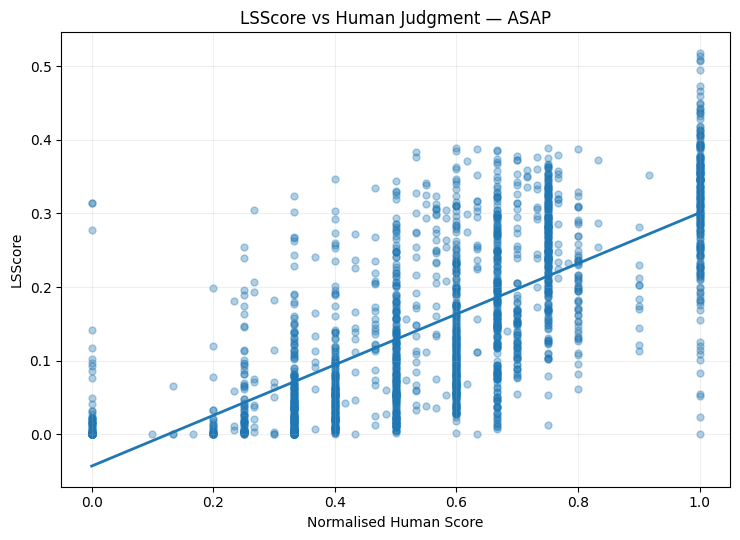

Saved:
thesis_figures/lsscore_vs_human_asap.png
thesis_figures/lsscore_vs_human_asap.pdf


In [ ]:
# ============================================================
# THESIS FIGURE — CURRENT DATASET
# LSScore vs Human Judgment on held-out TEST
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

FIGURE_DIR = "thesis_figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

dataset_label = (
    "PERSUADE 2.0"
    if DATASET_NAME.upper() == "PERSUADE"
    else DATASET_NAME
)

required_cols = {"normalised_human_score", "ls_score"}
missing_cols = required_cols.difference(test_df.columns)

if missing_cols:
    raise KeyError(
        "Cannot create thesis scatter plot. Missing TEST columns: "
        + ", ".join(sorted(missing_cols))
    )

x = test_df["normalised_human_score"].to_numpy(dtype=float)
y = test_df["ls_score"].to_numpy(dtype=float)

finite_mask = np.isfinite(x) & np.isfinite(y)
x = x[finite_mask]
y = y[finite_mask]

if len(x) < 2:
    raise ValueError("At least two valid TEST observations are required.")

# Linear trend line for visualisation only.
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = slope * x_line + intercept

fig, ax = plt.subplots(figsize=(7.5, 5.5))

ax.scatter(
    x,
    y,
    alpha=0.35,
    s=25,
)

ax.plot(
    x_line,
    y_line,
    linewidth=2,
)

ax.set_xlabel("Normalised Human Score")
ax.set_ylabel("LSScore")
ax.set_title(f"LSScore vs Human Judgment — {dataset_label}")
ax.grid(axis="both", alpha=0.20)

fig.tight_layout()

output_prefix = DATASET_NAME.lower().replace(" ", "_")

png_path = os.path.join(
    FIGURE_DIR,
    f"lsscore_vs_human_{output_prefix}.png",
)

pdf_path = os.path.join(
    FIGURE_DIR,
    f"lsscore_vs_human_{output_prefix}.pdf",
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Saved:")
print(png_path)
print(pdf_path)


### 12.1 Cross-dataset comparison figures

Run this cell after all three final notebooks have produced their `combined_results_*.csv` and `bootstrap_summary_*.csv` files. If the files are stored elsewhere, change `CROSS_DATASET_RESULTS_DIR` to that folder. The cell creates four cross-dataset figures: average correlation, correlation measures, pairwise accuracy, and bootstrap win rate.


In [ ]:
# ============================================================
# CROSS-DATASET THESIS FIGURES
# Run after CLASSE, ASAP, and PERSUADE final CSVs are available.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Mount Google Drive
# ------------------------------------------------------------

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass


# ------------------------------------------------------------
# Shared folder containing results from all three datasets
# ------------------------------------------------------------

CROSS_DATASET_RESULTS_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "LSScore/LSScore/results"
)

# Figures will be stored inside:
# results/thesis_figures/
CROSS_FIGURE_DIR = os.path.join(
    CROSS_DATASET_RESULTS_DIR,
    "thesis_figures",
)

os.makedirs(
    CROSS_FIGURE_DIR,
    exist_ok=True,
)


# ------------------------------------------------------------
# Final TEST result files
# ------------------------------------------------------------

result_files = {
    "CLASSE": "combined_results_classe.csv",
    "ASAP": "combined_results_asap.csv",
    "PERSUADE 2.0": "combined_results_persuade.csv",
}

bootstrap_files = {
    "CLASSE": "bootstrap_summary_classe.csv",
    "ASAP": "bootstrap_summary_asap.csv",
    "PERSUADE 2.0": "bootstrap_summary_persuade.csv",
}


# ------------------------------------------------------------
# Check that all required files exist
# ------------------------------------------------------------

required_files = (
    list(result_files.values())
    + list(bootstrap_files.values())
)

missing_files = [
    filename
    for filename in required_files
    if not os.path.exists(
        os.path.join(
            CROSS_DATASET_RESULTS_DIR,
            filename
        )
    )
]


if missing_files:

    print(
        "Cross-dataset figures were not generated because "
        "the following final result files are missing:"
    )

    for filename in missing_files:
        print(f"  - {filename}")

    print("\nExpected folder:")
    print(CROSS_DATASET_RESULTS_DIR)

    print(
        "\nRun the remaining dataset notebooks and save their "
        "final CSV files in this folder, then rerun this cell."
    )


else:

    print("All required result files found.")

    print("\nReading results from:")
    print(CROSS_DATASET_RESULTS_DIR)

    print("\nFigures will be saved to:")
    print(CROSS_FIGURE_DIR)


    # ========================================================
    # LOAD FINAL HELD-OUT TEST RESULTS
    # ========================================================

    result_frames = []

    for dataset, filename in result_files.items():

        path = os.path.join(
            CROSS_DATASET_RESULTS_DIR,
            filename,
        )

        df = pd.read_csv(path)

        df["dataset"] = dataset

        result_frames.append(df)


    all_results = pd.concat(
        result_frames,
        ignore_index=True,
    )


    # --------------------------------------------------------
    # Friendly metric names
    # --------------------------------------------------------

    metric_labels = {
        "ls_score": "LSScore",
        "bleu": "BLEU",
        "rouge": "ROUGE-L",
        "bert_score": "BERTScore",
    }

    all_results["metric_label"] = (
        all_results["metric"]
        .map(metric_labels)
    )


    metric_order = [
        "LSScore",
        "BLEU",
        "ROUGE-L",
        "BERTScore",
    ]

    dataset_order = [
        "CLASSE",
        "ASAP",
        "PERSUADE 2.0",
    ]


    # ========================================================
    # FIGURE 1
    # Average Correlation Across Datasets
    # ========================================================

    avg_df = (
        all_results
        .pivot(
            index="dataset",
            columns="metric_label",
            values="avg_correlation",
        )
        .reindex(dataset_order)
        [metric_order]
    )


    fig, ax = plt.subplots(
        figsize=(9, 5.5)
    )

    x = np.arange(
        len(avg_df.index)
    )

    width = 0.19


    for i, metric in enumerate(metric_order):

        values = (
            avg_df[metric]
            .to_numpy(dtype=float)
        )

        bars = ax.bar(
            x + (i - 1.5) * width,
            values,
            width,
            label=metric,
        )

        ax.bar_label(
            bars,
            fmt="%.3f",
            padding=3,
            fontsize=8,
        )


    ax.set_xticks(x)

    ax.set_xticklabels(
        avg_df.index
    )

    ax.set_xlabel(
        "Dataset"
    )

    ax.set_ylabel(
        "Average Correlation"
    )

    ax.set_title(
        "Average Correlation with Human Judgments Across Datasets"
    )

    ax.set_ylim(
        0,
        1
    )

    ax.legend(
        title="Metric",
        ncol=4,
    )

    ax.grid(
        axis="y",
        alpha=0.20,
    )

    fig.tight_layout()


    fig.savefig(
        os.path.join(
            CROSS_FIGURE_DIR,
            "figure_average_correlation_across_datasets.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        os.path.join(
            CROSS_FIGURE_DIR,
            "figure_average_correlation_across_datasets.pdf",
        ),
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


    # ========================================================
    # FIGURE 2
    # Pearson, Spearman, and Kendall Correlations
    # ========================================================

    ordered_rows = []


    for dataset in dataset_order:

        for metric in metric_order:

            row = all_results[
                (
                    all_results["dataset"]
                    == dataset
                )
                &
                (
                    all_results["metric_label"]
                    == metric
                )
            ]

            if not row.empty:

                ordered_rows.append({
                    "label":
                        f"{dataset}\n{metric}",

                    "pearson":
                        float(
                            row.iloc[0]["pearson_r"]
                        ),

                    "spearman":
                        float(
                            row.iloc[0]["spearman_r"]
                        ),

                    "kendall":
                        float(
                            row.iloc[0]["kendall_tau"]
                        ),
                })


    corr_df = pd.DataFrame(
        ordered_rows
    )

    x = np.arange(
        len(corr_df)
    )

    width = 0.25


    fig, ax = plt.subplots(
        figsize=(15, 6)
    )


    ax.bar(
        x - width,
        corr_df["pearson"],
        width,
        label="Pearson r",
    )

    ax.bar(
        x,
        corr_df["spearman"],
        width,
        label="Spearman ρ",
    )

    ax.bar(
        x + width,
        corr_df["kendall"],
        width,
        label="Kendall τ",
    )


    ax.set_xticks(x)

    ax.set_xticklabels(
        corr_df["label"],
        rotation=45,
        ha="right",
    )

    ax.set_xlabel(
        "Dataset and Metric"
    )

    ax.set_ylabel(
        "Correlation"
    )

    ax.set_title(
        "Correlation with Human Judgments Across Metrics and Datasets"
    )

    ax.set_ylim(
        0,
        1
    )

    ax.legend()

    ax.grid(
        axis="y",
        alpha=0.20,
    )

    fig.tight_layout()


    fig.savefig(
        os.path.join(
            CROSS_FIGURE_DIR,
            "figure_correlation_measures.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        os.path.join(
            CROSS_FIGURE_DIR,
            "figure_correlation_measures.pdf",
        ),
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


    # ========================================================
    # FIGURE 3
    # Pairwise Accuracy Across Datasets
    # ========================================================

    pairwise_df = (
        all_results
        .pivot(
            index="dataset",
            columns="metric_label",
            values="pairwise_accuracy",
        )
        .reindex(dataset_order)
        [metric_order]
    )


    fig, ax = plt.subplots(
        figsize=(9, 5.5)
    )

    x = np.arange(
        len(pairwise_df.index)
    )

    width = 0.19


    for i, metric in enumerate(metric_order):

        values = (
            pairwise_df[metric]
            .to_numpy(dtype=float)
        )

        bars = ax.bar(
            x + (i - 1.5) * width,
            values,
            width,
            label=metric,
        )

        ax.bar_label(
            bars,
            fmt="%.3f",
            padding=3,
            fontsize=8,
        )


    ax.set_xticks(x)

    ax.set_xticklabels(
        pairwise_df.index
    )

    ax.set_xlabel(
        "Dataset"
    )

    ax.set_ylabel(
        "Pairwise Accuracy"
    )

    ax.set_title(
        "Pairwise Accuracy Across Datasets"
    )

    ax.set_ylim(
        0,
        1
    )

    ax.legend(
        title="Metric",
        ncol=4,
    )

    ax.grid(
        axis="y",
        alpha=0.20,
    )

    fig.tight_layout()


    fig.savefig(
        os.path.join(
            CROSS_FIGURE_DIR,
            "figure_pairwise_accuracy.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        os.path.join(
            CROSS_FIGURE_DIR,
            "figure_pairwise_accuracy.pdf",
        ),
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


    # ========================================================
    # FIGURE 4
    # Bootstrap Win Rate Across Datasets
    # ========================================================

    # ========================================================
    # FIGURE 4
    # Bootstrap Win Rate Across Datasets
    # ========================================================

    bootstrap_rows = []

    for dataset, filename in bootstrap_files.items():

        path = os.path.join(
            CROSS_DATASET_RESULTS_DIR,
            filename,
        )

        df = pd.read_csv(path)
        row = df.iloc[0]

        competitor = metric_labels.get(
            row["baseline_competitor"],
            row["baseline_competitor"],
        )

        bootstrap_rows.append({
            "dataset": dataset,
            "competitor": competitor,
            "valid_resamples": int(
                row["valid_resamples"]
            ),
            "wins": int(
                row["lsscore_wins"]
            ),
            "win_rate": float(
                row["bootstrap_win_rate"]
            ) * 100,
        })


    bootstrap_plot_df = pd.DataFrame(
        bootstrap_rows
    )

    bootstrap_plot_df["dataset"] = pd.Categorical(
        bootstrap_plot_df["dataset"],
        categories=dataset_order,
        ordered=True,
    )

    bootstrap_plot_df = (
        bootstrap_plot_df
        .sort_values("dataset")
        .reset_index(drop=True)
    )


    fig, ax = plt.subplots(
        figsize=(9, 6)
    )

    x = np.arange(
        len(bootstrap_plot_df)
    )

    bars = ax.bar(
        x,
        bootstrap_plot_df["win_rate"],
        width=0.6,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:.1f}%"
            for value
            in bootstrap_plot_df["win_rate"]
        ],
        padding=4,
        fontsize=10,
    )

    labels = [
        f"{row.dataset}\nvs {row.competitor}"
        for row
        in bootstrap_plot_df.itertuples()
    ]

    ax.set_xticks(x)

    ax.set_xticklabels(
        labels,
        fontsize=10,
    )

    ax.set_xlabel(
        "Dataset and Strongest Baseline",
        labelpad=10,
    )

    ax.set_ylabel(
        "LSScore Bootstrap Win Rate (%)",
        labelpad=10,
    )

    ax.set_title(
        "Bootstrap Stability of LSScore Across Datasets",
        fontsize=14,
        pad=20,
    )

    # Extra space above 100% labels
    ax.set_ylim(
        0,
        115,
    )

    ax.axhline(
        50,
        linestyle="--",
        linewidth=1,
    )

    ax.grid(
        axis="y",
        alpha=0.20,
    )

    ax.set_axisbelow(True)

    fig.tight_layout()

    fig.subplots_adjust(
        top=0.86
    )

    fig.savefig(
        os.path.join(
            CROSS_FIGURE_DIR,
            "figure_bootstrap_win_rate.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        os.path.join(
            CROSS_FIGURE_DIR,
            "figure_bootstrap_win_rate.pdf",
        ),
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


    print(
        "\nCross-dataset thesis figures saved successfully."
    )

    print("\nSaved to:")
    print(CROSS_FIGURE_DIR)

    print(
        "\nBootstrap summary used for Figure 4:"
    )

    print(
        bootstrap_plot_df[
            [
                "dataset",
                "competitor",
                "valid_resamples",
                "wins",
                "win_rate",
            ]
        ].to_string(index=False)
    )


    # ========================================================
    # FINAL SUMMARY
    # ========================================================

    print(
        "\nCross-dataset thesis figures saved successfully."
    )

    print("\nSaved to:")
    print(
        CROSS_FIGURE_DIR
    )


    print(
        "\nGenerated figures:"
    )

    for filename in sorted(
        os.listdir(
            CROSS_FIGURE_DIR
        )
    ):
        print(
            " -",
            filename
        )


    print(
        "\nBootstrap summary used for Figure 4:"
    )

    print(
        bootstrap_plot_df[
            [
                "dataset",
                "competitor",
                "valid_resamples",
                "wins",
                "win_rate",
            ]
        ].to_string(
            index=False
        )
    )